In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [32]:

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load Dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=10000
)

# Padding
max_length = 200

X_train = pad_sequences(
    X_train, maxlen=max_length, padding="post", truncating="post"
)

X_test = pad_sequences(
    X_test, maxlen=max_length, padding="post", truncating="post"
)

print(X_train.shape)
print(X_test.shape)

(25000, 200)
(25000, 200)


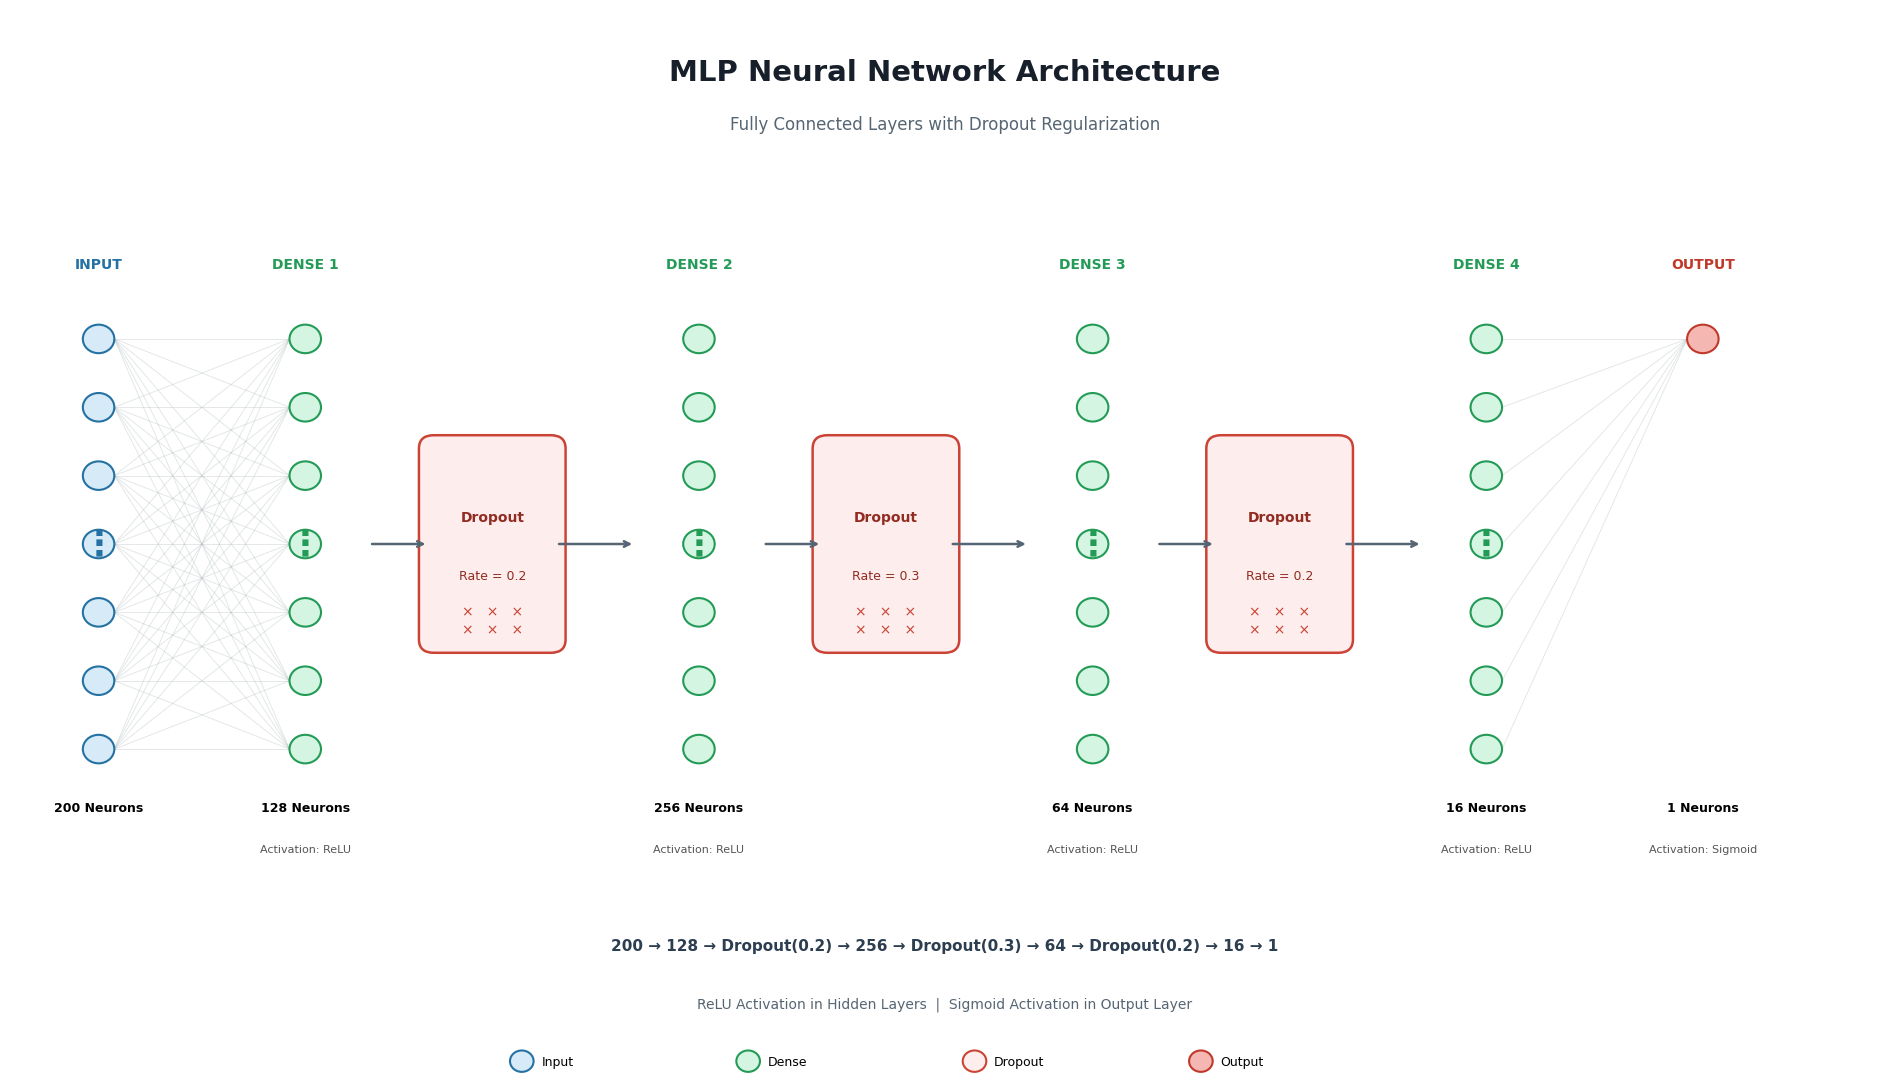

In [91]:

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch
import numpy as np

# ==========================================
# 1. Figure Setup
# ==========================================

fig, ax = plt.subplots(figsize=(19, 11))

ax.set_xlim(0, 19)
ax.set_ylim(0, 12)
ax.axis("off")

fig.patch.set_facecolor("white")

# ==========================================
# 2. Architecture Configuration
# ==========================================

layers_config = [
    {"name": "INPUT", "neurons": 200, "type": "input"},
    {"name": "DENSE 1", "neurons": 128, "activation": "ReLU", "type": "dense"},
    {"name": "DROPOUT", "rate": "0.2", "type": "dropout"},
    {"name": "DENSE 2", "neurons": 256, "activation": "ReLU", "type": "dense"},
    {"name": "DROPOUT", "rate": "0.3", "type": "dropout"},
    {"name": "DENSE 3", "neurons": 64, "activation": "ReLU", "type": "dense"},
    {"name": "DROPOUT", "rate": "0.2", "type": "dropout"},
    {"name": "DENSE 4", "neurons": 16, "activation": "ReLU", "type": "dense"},
    {"name": "OUTPUT", "neurons": 1, "activation": "Sigmoid", "type": "output"}
]

x_positions = [0.9, 3.0, 4.9, 7.0, 8.9, 11.0, 12.9, 15.0, 17.2]

# ==========================================
# 3. Drawing Functions
# ==========================================

def draw_neuron(x, y, color, edge, radius=0.16):

    neuron = Circle(
        (x, y),
        radius,
        facecolor=color,
        edgecolor=edge,
        linewidth=1.5,
        zorder=3
    )

    ax.add_patch(neuron)


def draw_dense_layer(x, name, count, activation, kind="dense"):

    # Number of neurons shown in the drawing
    visible = min(count, 7)

    y_positions = np.linspace(8.3, 3.7, visible)

    if kind == "input":
        fill = "#D6EAF8"
        edge = "#2471A3"
    elif kind == "output":
        fill = "#F5B7B1"
        edge = "#C0392B"
    else:
        fill = "#D5F5E3"
        edge = "#239B56"

    for y in y_positions:
        draw_neuron(x, y, fill, edge)

    if count > visible:
        ax.text(
            x, 6.0, "⋮",
            ha="center",
            va="center",
            fontsize=25,
            color=edge,
            fontweight="bold"
        )

    # Layer title
    ax.text(
        x, 9.1,
        name,
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=edge
    )

    # Neuron count
    ax.text(
        x, 3.0,
        f"{count} Neurons",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

    if activation:
        ax.text(
            x, 2.55,
            f"Activation: {activation}",
            ha="center",
            fontsize=8,
            color="#555555"
        )

    return y_positions


def connect_dense_layers(x1, y1, x2, y2):

    # Fully connected representation
    for a in y1:
        for b in y2:

            ax.plot(
                [x1 + 0.16, x2 - 0.16],
                [a, b],
                color="#AAB7B8",
                linewidth=0.65,
                alpha=0.35,
                zorder=1
            )


def draw_dropout(x, rate):

    width = 1.25
    height = 2.2

    box = FancyBboxPatch(
        (x - width / 2, 4.9),
        width,
        height,
        boxstyle="round,pad=0.12,rounding_size=0.15",
        facecolor="#FDEDEC",
        edgecolor="#CB4335",
        linewidth=1.8,
        zorder=2
    )

    ax.add_patch(box)

    ax.text(
        x, 6.3,
        "Dropout",
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#922B21"
    )

    ax.text(
        x, 5.65,
        f"Rate = {rate}",
        ha="center",
        va="center",
        fontsize=9,
        color="#922B21"
    )

    # Small dots represent randomly dropped neurons
    for y in [5.2, 5.0]:
        ax.text(
            x, y,
            "×   ×   ×",
            ha="center",
            fontsize=10,
            color="#CB4335"
        )


def draw_flow_arrow(x1, x2):

    ax.annotate(
        "",
        xy=(x2 - 0.65, 6.0),
        xytext=(x1 + 0.65, 6.0),
        arrowprops={
            "arrowstyle": "->",
            "color": "#566573",
            "linewidth": 1.8,
            "shrinkA": 2,
            "shrinkB": 2
        },
        zorder=4
    )


# ==========================================
# 4. Title
# ==========================================

ax.text(
    9.5, 11.2,
    "MLP Neural Network Architecture",
    ha="center",
    fontsize=21,
    fontweight="bold",
    color="#17202A"
)

ax.text(
    9.5, 10.65,
    "Fully Connected Layers with Dropout Regularization",
    ha="center",
    fontsize=12,
    color="#566573"
)

# ==========================================
# 5. Draw All Layers
# ==========================================

layer_positions = []

for i, layer in enumerate(layers_config):

    x = x_positions[i]

    if layer["type"] == "dropout":

        draw_dropout(x, layer["rate"])
        layer_positions.append(None)

    else:

        positions = draw_dense_layer(
            x=x,
            name=layer["name"],
            count=layer["neurons"],
            activation=layer.get("activation"),
            kind=layer["type"]
        )

        layer_positions.append(positions)


# ==========================================
# 6. Connect Dense Layers and Dropout
# ==========================================

for i in range(len(layers_config) - 1):

    current = layers_config[i]
    next_layer = layers_config[i + 1]

    x1 = x_positions[i]
    x2 = x_positions[i + 1]

    if current["type"] != "dropout" and next_layer["type"] != "dropout":

        connect_dense_layers(
            x1,
            layer_positions[i],
            x2,
            layer_positions[i + 1]
        )

    else:

        draw_flow_arrow(x1, x2)


# ==========================================
# 7. Bottom Summary
# ==========================================

ax.text(
    9.5, 1.45,
    "200 → 128 → Dropout(0.2) → 256 → Dropout(0.3) "
    "→ 64 → Dropout(0.2) → 16 → 1",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#2C3E50"
)

ax.text(
    9.5, 0.8,
    "ReLU Activation in Hidden Layers  |  Sigmoid Activation in Output Layer",
    ha="center",
    fontsize=10,
    color="#566573"
)

# ==========================================
# 8. Legend
# ==========================================

legend_items = [
    ("Input", "#D6EAF8", "#2471A3"),
    ("Dense", "#D5F5E3", "#239B56"),
    ("Dropout", "#FDEDEC", "#CB4335"),
    ("Output", "#F5B7B1", "#C0392B")
]

for i, (label, fill, edge) in enumerate(legend_items):

    x = 5.2 + i * 2.3

    ax.add_patch(
        Circle(
            (x, 0.2),
            0.12,
            facecolor=fill,
            edgecolor=edge,
            linewidth=1.5
        )
    )

    ax.text(
        x + 0.2, 0.2,
        label,
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


In [33]:

model = Sequential([
    layers.Input(shape=(200,)),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

In [34]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │        25,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,257 (297.88 KB)

 Trainable params: 76,257 (297.88 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5011 - loss: 5.4541 - val_accuracy: 0.4938 - val_loss: 0.6933
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5006 - loss: 0.7812 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4992 - loss: 0.7162 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4995 - loss: 0.7326 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5002 - loss: 0.6963 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4995 - loss: 0.6976 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4999 - loss: 0.6936 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5001 - loss: 0.7020 - val_accuracy: 0.

In [36]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5000 - loss: 0.6932
Test Loss: 0.6931570172309875
Test Accuracy: 0.5


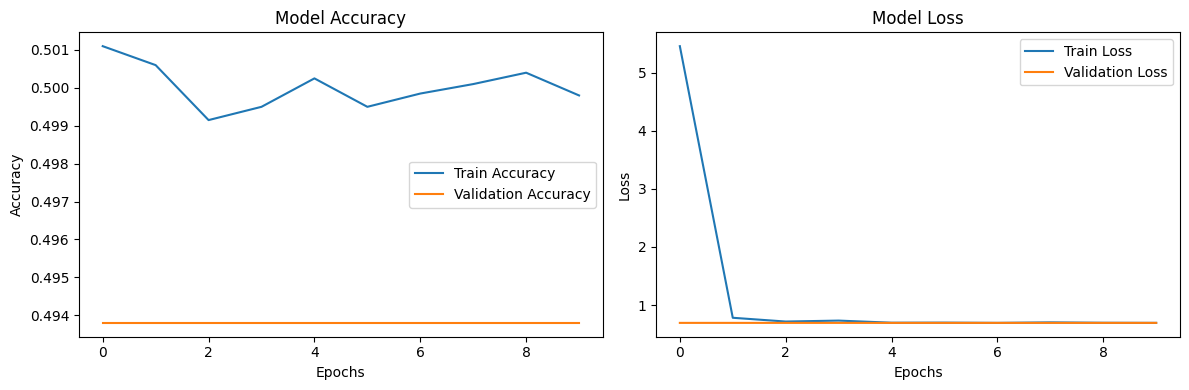

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

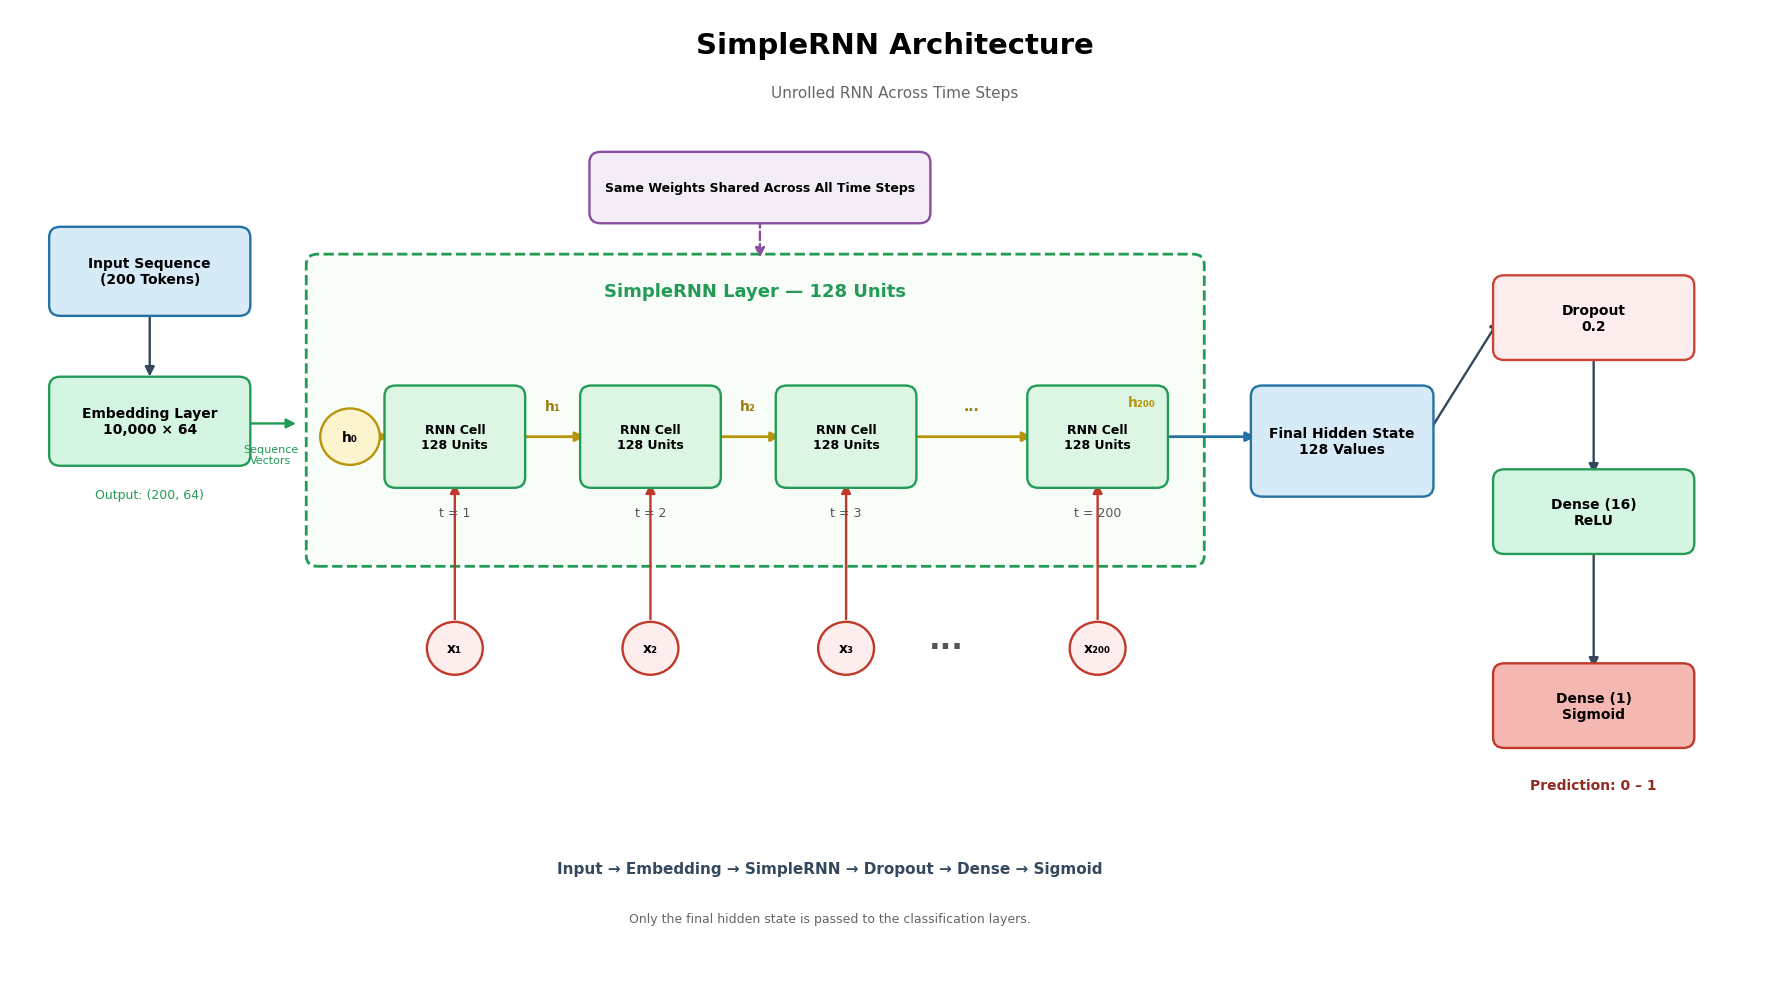

In [95]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

# ==========================================
# 1. Figure Setup
# ==========================================

fig, ax = plt.subplots(figsize=(18, 10))

ax.set_xlim(0, 19)
ax.set_ylim(0, 11)
ax.axis("off")

# ==========================================
# 2. Drawing Functions
# ==========================================

def draw_box(x, y, w, h, label, face, edge,
             fontsize=10, linestyle="-"):

    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        facecolor=face,
        edgecolor=edge,
        linewidth=1.7,
        linestyle=linestyle,
        zorder=3
    )

    ax.add_patch(patch)

    ax.text(
        x + w / 2,
        y + h / 2,
        label,
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight="bold",
        zorder=4
    )


def draw_circle(x, y, label, face, edge, radius=0.32):

    circle = Circle(
        (x, y),
        radius,
        facecolor=face,
        edgecolor=edge,
        linewidth=1.7,
        zorder=3
    )

    ax.add_patch(circle)

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        zorder=4
    )


def arrow(x1, y1, x2, y2, color="#34495E",
          width=1.7, style="-", rad=0):

    ax.add_patch(
        FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle="-|>",
            mutation_scale=14,
            linewidth=width,
            color=color,
            linestyle=style,
            connectionstyle=f"arc3,rad={rad}",
            zorder=2
        )
    )


# ==========================================
# 3. Title
# ==========================================

ax.text(
    9.5, 10.5,
    "SimpleRNN Architecture",
    ha="center",
    fontsize=21,
    fontweight="bold"
)

ax.text(
    9.5, 10.0,
    "Unrolled RNN Across Time Steps",
    ha="center",
    fontsize=11,
    color="#666666"
)

# ==========================================
# 4. Input and Embedding
# ==========================================

draw_box(
    0.5, 7.6, 2.0, 0.85,
    "Input Sequence\n(200 Tokens)",
    "#D6EAF8", "#2471A3", 10
)

draw_box(
    0.5, 5.9, 2.0, 0.85,
    "Embedding Layer\n10,000 × 64",
    "#D5F5E3", "#239B56", 10
)

arrow(1.5, 7.6, 1.5, 6.8)

ax.text(
    1.5, 5.45,
    "Output: (200, 64)",
    ha="center",
    fontsize=9,
    color="#239B56"
)

# ==========================================
# 5. RNN Layer Boundary
# ==========================================

boundary = FancyBboxPatch(
    (3.3, 4.8), 9.4, 3.3,
    boxstyle="round,pad=0.12",
    facecolor="#F8FDF8",
    edgecolor="#239B56",
    linewidth=2,
    linestyle="--",
    zorder=0
)

ax.add_patch(boundary)

ax.text(
    8.0, 7.75,
    "SimpleRNN Layer — 128 Units",
    ha="center",
    fontsize=13,
    fontweight="bold",
    color="#239B56"
)

# ==========================================
# 6. Repeated RNN Cells
# ==========================================

cell_x = [4.1, 6.2, 8.3, 11.0]
cell_width = 1.35
cell_y = 5.65
cell_height = 1.0

time_labels = ["t = 1", "t = 2", "t = 3", "t = 200"]

for x, time in zip(cell_x, time_labels):

    draw_box(
        x, cell_y, cell_width, cell_height,
        "RNN Cell\n128 Units",
        "#DDF5E3", "#239B56", 9
    )

    ax.text(
        x + cell_width / 2,
        5.25,
        time,
        ha="center",
        fontsize=9,
        color="#555555"
    )

# ==========================================
# 7. Hidden State Connections
# ==========================================

# Initial hidden state
draw_circle(
    3.65, 6.15,
    "h₀",
    "#FCF3CF", "#B7950B"
)

arrow(
    3.97, 6.15,
    4.1, 6.15,
    color="#B7950B"
)

# Connections between recurrent cells
for i in range(3):

    start_x = cell_x[i] + cell_width
    end_x = cell_x[i + 1]

    arrow(
        start_x, 6.15,
        end_x, 6.15,
        color="#B7950B",
        width=2.0
    )

    if i < 2:
        label = ["h₁", "h₂"][i]
    else:
        label = "..."

    ax.text(
        (start_x + end_x) / 2,
        6.45,
        label,
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#9A7D0A"
    )

# Final hidden state
ax.text(
    12.15, 6.5,
    "h₂₀₀",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#B7950B"
)

# ==========================================
# 8. Input at Each Time Step
# ==========================================

input_x = [4.775, 6.875, 8.975, 11.675]
input_labels = ["x₁", "x₂", "x₃", "x₂₀₀"]

for x, label in zip(input_x, input_labels):

    draw_circle(
        x, 3.75,
        label,
        "#FDEDEC", "#C0392B",
        radius=0.3
    )

    arrow(
        x, 4.05,
        x, 5.65,
        color="#C0392B"
    )

# Ellipsis between time steps
ax.text(
    10.05, 3.75,
    "...",
    ha="center",
    fontsize=22,
    fontweight="bold",
    color="#555555"
)

# Embedding output explanation
arrow(
    2.5, 6.3,
    3.1, 6.3,
    color="#239B56"
)

ax.text(
    2.8, 5.85,
    "Sequence\nVectors",
    ha="center",
    fontsize=8,
    color="#239B56"
)

# ==========================================
# 9. Shared Weights
# ==========================================

draw_box(
    6.3, 8.65, 3.5, 0.65,
    "Same Weights Shared Across All Time Steps",
    "#F4ECF7", "#884EA0", 9
)

arrow(
    8.05, 8.65,
    8.05, 8.15,
    color="#884EA0",
    style="--"
)

# ==========================================
# 10. Final Hidden State
# ==========================================

draw_box(
    13.4, 5.55, 1.8, 1.1,
    "Final Hidden State\n128 Values",
    "#D6EAF8", "#2471A3", 10
)

arrow(
    12.35, 6.15,
    13.4, 6.15,
    color="#2471A3",
    width=2
)

# ==========================================
# 11. Classification Layers
# ==========================================

draw_box(
    16.0, 7.1, 2.0, 0.8,
    "Dropout\n0.2",
    "#FDEDEC", "#CB4335", 10
)

draw_box(
    16.0, 4.9, 2.0, 0.8,
    "Dense (16)\nReLU",
    "#D5F5E3", "#239B56", 10
)

draw_box(
    16.0, 2.7, 2.0, 0.8,
    "Dense (1)\nSigmoid",
    "#F5B7B1", "#C0392B", 10
)

# Classification flow
arrow(15.2, 6.15, 16.0, 7.5)
arrow(17.0, 7.1, 17.0, 5.7)
arrow(17.0, 4.9, 17.0, 3.5)

ax.text(
    17.0, 2.15,
    "Prediction: 0 – 1",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#922B21"
)

# ==========================================
# 12. Footer
# ==========================================

ax.text(
    8.8, 1.2,
    "Input → Embedding → SimpleRNN → Dropout → Dense → Sigmoid",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#34495E"
)

ax.text(
    8.8, 0.65,
    "Only the final hidden state is passed to the classification layers.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout()
plt.show()


In [38]:


model = Sequential([
    layers.Input(shape=(200,)),

    layers.Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),

    layers.SimpleRNN(128),

    layers.Dropout(0.2),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

In [39]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 666,785 (2.54 MB)

 Trainable params: 666,785 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.4989 - loss: 0.6967 - val_accuracy: 0.4992 - val_loss: 0.6932
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.4938 - loss: 0.6935 - val_accuracy: 0.5012 - val_loss: 0.6931
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.4960 - loss: 0.6932 - val_accuracy: 0.5054 - val_loss: 0.6931
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.4992 - loss: 0.6933 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.4992 - loss: 0.6933 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5381 - loss: 0.6870 - val_accuracy: 0.6092 - val_loss: 0.6719
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 20ms/step - accuracy: 0.6898 - loss: 0.5864 - val_accuracy: 0.6486 - val_loss: 0.6289
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.6880 - loss: 0.5836 - 

In [41]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6016 - loss: 0.6592
Test Loss: 0.6591993570327759
Test Accuracy: 0.6015599966049194


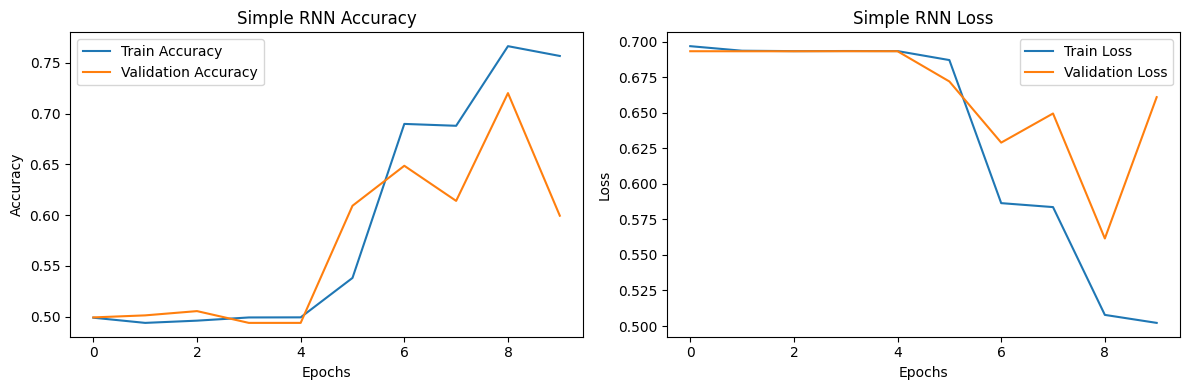

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Simple RNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Simple RNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

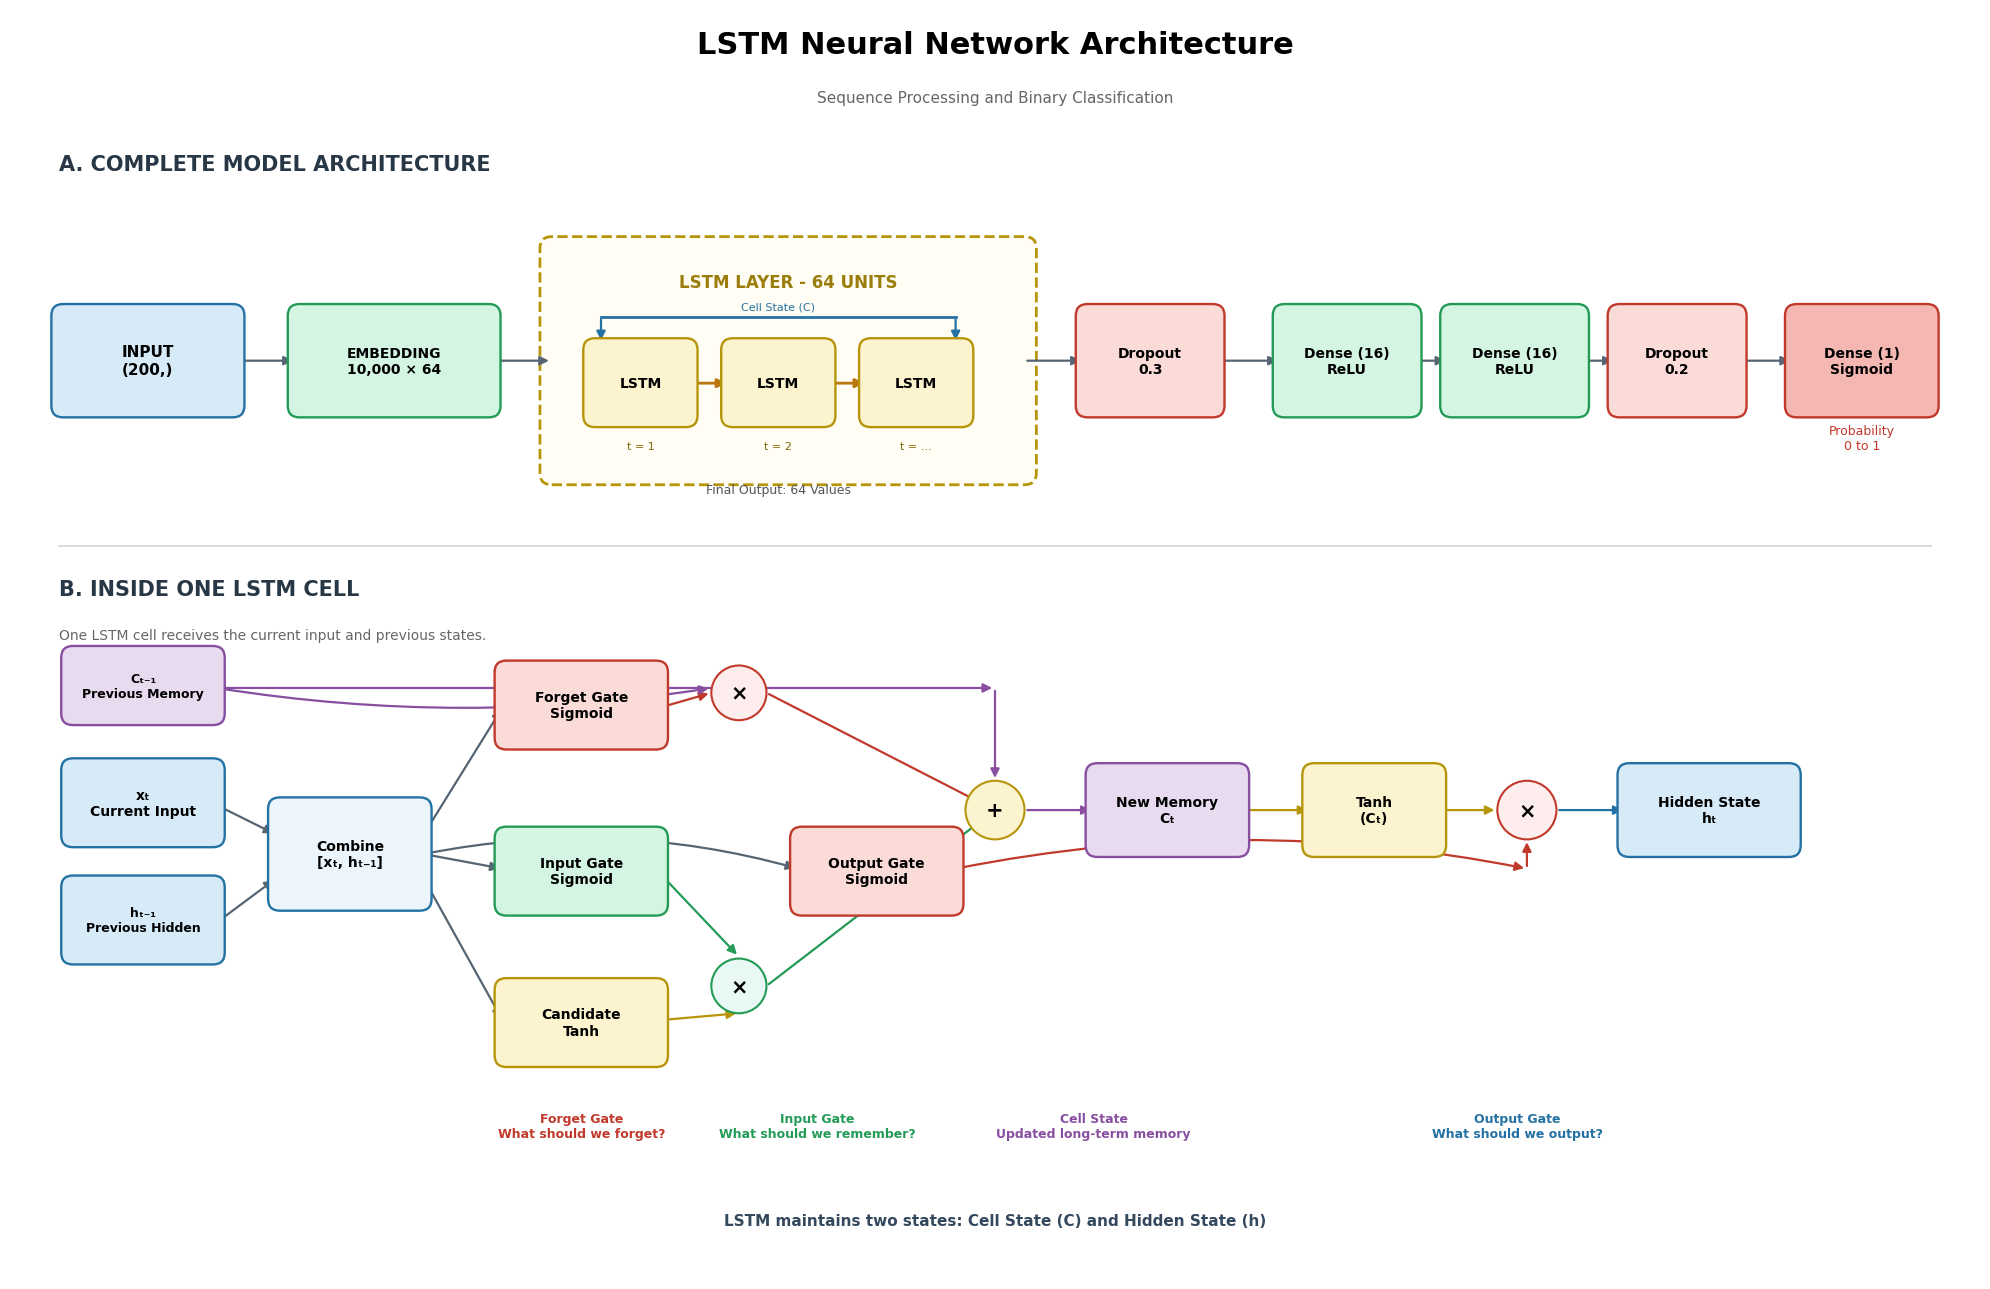

In [96]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle

# ==================================================
# 1. Figure Setup
# ==================================================

fig, ax = plt.subplots(figsize=(20, 13))

ax.set_xlim(0, 20)
ax.set_ylim(0, 13)
ax.axis("off")

# ==================================================
# 2. Colors
# ==================================================

BLUE = "#D6EAF8"
BLUE_EDGE = "#2471A3"

GREEN = "#D5F5E3"
GREEN_EDGE = "#239B56"

YELLOW = "#FCF3CF"
YELLOW_EDGE = "#B7950B"

RED = "#FADBD8"
RED_EDGE = "#C0392B"

PURPLE = "#E8DAEF"
PURPLE_EDGE = "#884EA0"

GRAY = "#566573"


# ==================================================
# 3. Drawing Functions
# ==================================================

def box(x, y, w, h, label, face, edge, fs=10):

    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        facecolor=face,
        edgecolor=edge,
        linewidth=1.7,
        zorder=3
    )

    ax.add_patch(patch)

    ax.text(
        x + w / 2,
        y + h / 2,
        label,
        ha="center",
        va="center",
        fontsize=fs,
        fontweight="bold",
        zorder=4
    )


def arrow(x1, y1, x2, y2, color=GRAY, width=1.6, style="-", rad=0):

    ax.add_patch(
        FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle="-|>",
            mutation_scale=13,
            linewidth=width,
            color=color,
            linestyle=style,
            connectionstyle=f"arc3,rad={rad}",
            zorder=2
        )
    )


def section_title(x, y, title):

    ax.text(
        x, y, title,
        fontsize=15,
        fontweight="bold",
        color="#273746"
    )


# ==================================================
# 4. Main Title
# ==================================================

ax.text(
    10, 12.55,
    "LSTM Neural Network Architecture",
    ha="center",
    fontsize=22,
    fontweight="bold"
)

ax.text(
    10, 12.05,
    "Sequence Processing and Binary Classification",
    ha="center",
    fontsize=11,
    color="#666666"
)


# ==================================================
# 5. Complete Model Architecture
# ==================================================

section_title(0.5, 11.35, "A. COMPLETE MODEL ARCHITECTURE")

# Input
box(
    0.5, 8.9, 1.8, 1.0,
    "INPUT\n(200,)",
    BLUE, BLUE_EDGE, 11
)

# Embedding
box(
    2.9, 8.9, 2.0, 1.0,
    "EMBEDDING\n10,000 × 64",
    GREEN, GREEN_EDGE, 10
)

arrow(2.3, 9.4, 2.9, 9.4)

# LSTM Layer Boundary
boundary = FancyBboxPatch(
    (5.5, 8.25), 4.8, 2.3,
    boxstyle="round,pad=0.12",
    facecolor="#FFFDF4",
    edgecolor=YELLOW_EDGE,
    linewidth=2,
    linestyle="--",
    zorder=0
)

ax.add_patch(boundary)

ax.text(
    7.9, 10.15,
    "LSTM LAYER - 64 UNITS",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="#9A7D0A"
)

# Unrolled LSTM Cells
lstm_x = [5.9, 7.3, 8.7]

for i, x in enumerate(lstm_x):

    box(
        x, 8.8, 1.0, 0.75,
        "LSTM",
        YELLOW, YELLOW_EDGE, 10
    )

    ax.text(
        x + 0.5, 8.5,
        ["t = 1", "t = 2", "t = ..."][i],
        ha="center",
        fontsize=8,
        color="#7D6608"
    )

# Hidden state connections
for i in range(2):

    arrow(
        lstm_x[i] + 1.0, 9.17,
        lstm_x[i + 1], 9.17,
        color="#B9770E",
        width=2
    )

# Cell state connection
ax.plot(
    [6.0, 9.6],
    [9.85, 9.85],
    color="#2471A3",
    linewidth=2
)

arrow(6.0, 9.85, 6.0, 9.58, color="#2471A3")
arrow(9.6, 9.85, 9.6, 9.58, color="#2471A3")

ax.text(
    7.8, 9.92,
    "Cell State (C)",
    ha="center",
    fontsize=8,
    color=BLUE_EDGE
)

ax.text(
    7.8, 8.05,
    "Final Output: 64 Values",
    ha="center",
    fontsize=9,
    color="#555555"
)

arrow(4.9, 9.4, 5.5, 9.4)

# Dropout 0.3
box(
    10.9, 8.9, 1.35, 1.0,
    "Dropout\n0.3",
    RED, RED_EDGE, 10
)

arrow(10.3, 9.4, 10.9, 9.4)

# Dense 16 - First
box(
    12.9, 8.9, 1.35, 1.0,
    "Dense (16)\nReLU",
    GREEN, GREEN_EDGE, 10
)

arrow(12.25, 9.4, 12.9, 9.4)

# Dense 16 - Second
box(
    14.6, 8.9, 1.35, 1.0,
    "Dense (16)\nReLU",
    GREEN, GREEN_EDGE, 10
)

arrow(14.25, 9.4, 14.6, 9.4)

# Dropout 0.2
box(
    16.3, 8.9, 1.25, 1.0,
    "Dropout\n0.2",
    RED, RED_EDGE, 10
)

arrow(15.95, 9.4, 16.3, 9.4)

# Output
box(
    18.1, 8.9, 1.4, 1.0,
    "Dense (1)\nSigmoid",
    "#F5B7B1", RED_EDGE, 10
)

arrow(17.55, 9.4, 18.1, 9.4)

ax.text(
    18.8, 8.5,
    "Probability\n0 to 1",
    ha="center",
    fontsize=9,
    color=RED_EDGE
)


# ==================================================
# 6. Divider
# ==================================================

ax.plot(
    [0.5, 19.5],
    [7.5, 7.5],
    color="#D5D8DC",
    linewidth=1.3
)


# ==================================================
# 7. LSTM Cell Internal Architecture
# ==================================================

section_title(0.5, 7.0, "B. INSIDE ONE LSTM CELL")

ax.text(
    0.5, 6.55,
    "One LSTM cell receives the current input and previous states.",
    fontsize=10,
    color="#666666"
)

# Inputs
box(
    0.6, 4.5, 1.5, 0.75,
    "xₜ\nCurrent Input",
    BLUE, BLUE_EDGE, 10
)

box(
    0.6, 3.3, 1.5, 0.75,
    "hₜ₋₁\nPrevious Hidden",
    BLUE, BLUE_EDGE, 9
)

box(
    0.6, 5.75, 1.5, 0.65,
    "Cₜ₋₁\nPrevious Memory",
    PURPLE, PURPLE_EDGE, 9
)

# Concatenation
box(
    2.7, 3.85, 1.5, 1.0,
    "Combine\n[xₜ, hₜ₋₁]",
    "#EBF5FB", BLUE_EDGE, 10
)

arrow(2.1, 4.85, 2.7, 4.55)
arrow(2.1, 3.65, 2.7, 4.1)

# Forget Gate
box(
    5.0, 5.5, 1.6, 0.75,
    "Forget Gate\nSigmoid",
    RED, RED_EDGE, 10
)

# Input Gate
box(
    5.0, 3.8, 1.6, 0.75,
    "Input Gate\nSigmoid",
    GREEN, GREEN_EDGE, 10
)

# Candidate Memory
box(
    5.0, 2.25, 1.6, 0.75,
    "Candidate\nTanh",
    YELLOW, YELLOW_EDGE, 10
)

# Output Gate
box(
    8.0, 3.8, 1.6, 0.75,
    "Output Gate\nSigmoid",
    RED, RED_EDGE, 10
)

# Branches from combined input
arrow(4.2, 4.55, 5.0, 5.85)
arrow(4.2, 4.35, 5.0, 4.2)
arrow(4.2, 4.1, 5.0, 2.65)
arrow(4.2, 4.35, 8.0, 4.2, rad=-0.12)

# Forget operation
draw_circle = Circle(
    (7.4, 6.0), 0.28,
    facecolor="#FDEDEC",
    edgecolor=RED_EDGE,
    linewidth=1.5,
    zorder=3
)
ax.add_patch(draw_circle)

ax.text(7.4, 6.0, "×", ha="center", va="center",
        fontsize=15, fontweight="bold")

arrow(6.6, 5.85, 7.12, 6.0, color=RED_EDGE)
arrow(2.1, 6.05, 7.12, 6.05, color=PURPLE_EDGE, rad=0.08)

# Input candidate operation
ax.add_patch(Circle(
    (7.4, 3.0), 0.28,
    facecolor="#E8F8F5",
    edgecolor=GREEN_EDGE,
    linewidth=1.5,
    zorder=3
))

ax.text(7.4, 3.0, "×", ha="center", va="center",
        fontsize=15, fontweight="bold")

arrow(6.6, 4.15, 7.4, 3.3, color=GREEN_EDGE)
arrow(6.6, 2.65, 7.4, 2.72, color=YELLOW_EDGE)

# Add operation
ax.add_patch(Circle(
    (10.0, 4.8), 0.3,
    facecolor="#FCF3CF",
    edgecolor=YELLOW_EDGE,
    linewidth=1.5,
    zorder=3
))

ax.text(10.0, 4.8, "+", ha="center", va="center",
        fontsize=15, fontweight="bold")

# Previous memory to add operation
arrow(2.1, 6.05, 10.0, 6.05, color=PURPLE_EDGE)
arrow(10.0, 6.05, 10.0, 5.1, color=PURPLE_EDGE)

# Forget product to addition
arrow(7.68, 6.0, 10.0, 4.8, color=RED_EDGE)

# Input product to addition
arrow(7.68, 3.0, 10.0, 4.8, color=GREEN_EDGE)

# New cell state
box(
    11.0, 4.4, 1.5, 0.8,
    "New Memory\nCₜ",
    PURPLE, PURPLE_EDGE, 10
)

arrow(10.3, 4.8, 11.0, 4.8, color=PURPLE_EDGE)

# Tanh memory
box(
    13.2, 4.4, 1.3, 0.8,
    "Tanh\n(Cₜ)",
    YELLOW, YELLOW_EDGE, 10
)

arrow(12.5, 4.8, 13.2, 4.8, color=YELLOW_EDGE)

# Output multiplication
ax.add_patch(Circle(
    (15.4, 4.8), 0.3,
    facecolor="#FDEDEC",
    edgecolor=RED_EDGE,
    linewidth=1.5,
    zorder=3
))

ax.text(15.4, 4.8, "×", ha="center", va="center",
        fontsize=15, fontweight="bold")

arrow(14.5, 4.8, 15.1, 4.8, color=YELLOW_EDGE)

# Output gate connection
arrow(9.6, 4.2, 15.4, 4.2, color=RED_EDGE, rad=-0.1)
arrow(15.4, 4.2, 15.4, 4.5, color=RED_EDGE)

# Final hidden state
box(
    16.4, 4.4, 1.7, 0.8,
    "Hidden State\nhₜ",
    BLUE, BLUE_EDGE, 10
)

arrow(15.7, 4.8, 16.4, 4.8, color=BLUE_EDGE)

# ==================================================
# 8. Gate Explanations
# ==================================================

ax.text(
    5.8, 1.45,
    "Forget Gate\nWhat should we forget?",
    ha="center",
    fontsize=9,
    color=RED_EDGE,
    fontweight="bold"
)

ax.text(
    8.2, 1.45,
    "Input Gate\nWhat should we remember?",
    ha="center",
    fontsize=9,
    color=GREEN_EDGE,
    fontweight="bold"
)

ax.text(
    11.0, 1.45,
    "Cell State\nUpdated long-term memory",
    ha="center",
    fontsize=9,
    color=PURPLE_EDGE,
    fontweight="bold"
)

ax.text(
    15.3, 1.45,
    "Output Gate\nWhat should we output?",
    ha="center",
    fontsize=9,
    color=BLUE_EDGE,
    fontweight="bold"
)

# ==================================================
# 9. Footer
# ==================================================

ax.text(
    10, 0.55,
    "LSTM maintains two states: Cell State (C) and Hidden State (h)",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#34495E"
)

plt.tight_layout()
plt.show()


In [43]:
model = Sequential([
    layers.Input(shape=(200,)),

    layers.Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),

    layers.LSTM(64),

    layers.Dropout(0.3),

    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

In [44]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 674,353 (2.57 MB)

 Trainable params: 674,353 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.6180 - loss: 0.6505 - val_accuracy: 0.5422 - val_loss: 0.6902
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.7308 - loss: 0.5383 - val_accuracy: 0.7938 - val_loss: 0.4463
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.8637 - loss: 0.3448 - val_accuracy: 0.8458 - val_loss: 0.3649
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9069 - loss: 0.2578 - val_accuracy: 0.8176 - val_loss: 0.4995
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9255 - loss: 0.2129 - val_accuracy: 0.8344 - val_loss: 0.4661
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8979 - loss: 0.2609 - val_accuracy: 0.8344 - val_loss: 0.4281
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9235 - loss: 0.2056 - val_accuracy: 0.8540 - val_loss: 0.4850
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9548 - loss: 0.1344 - val

In [46]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8227 - loss: 0.6764
Test Loss: 0.6763976812362671
Test Accuracy: 0.8226799964904785


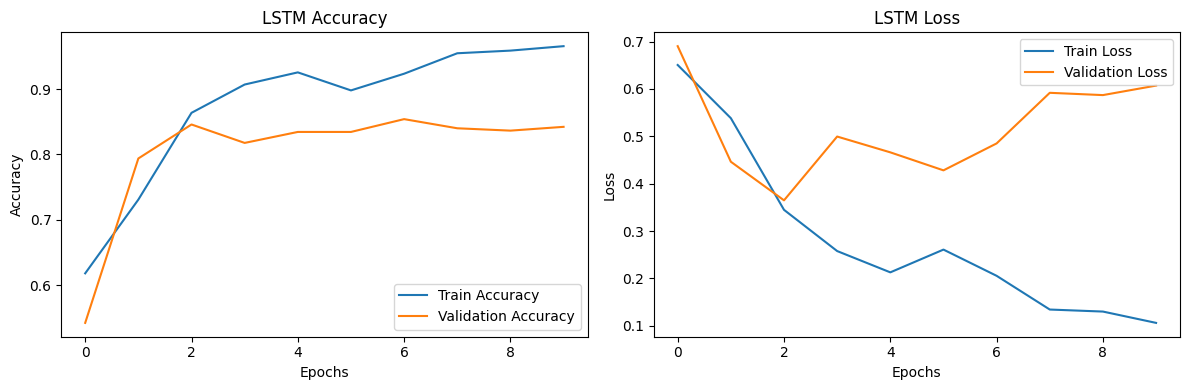

In [47]:


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

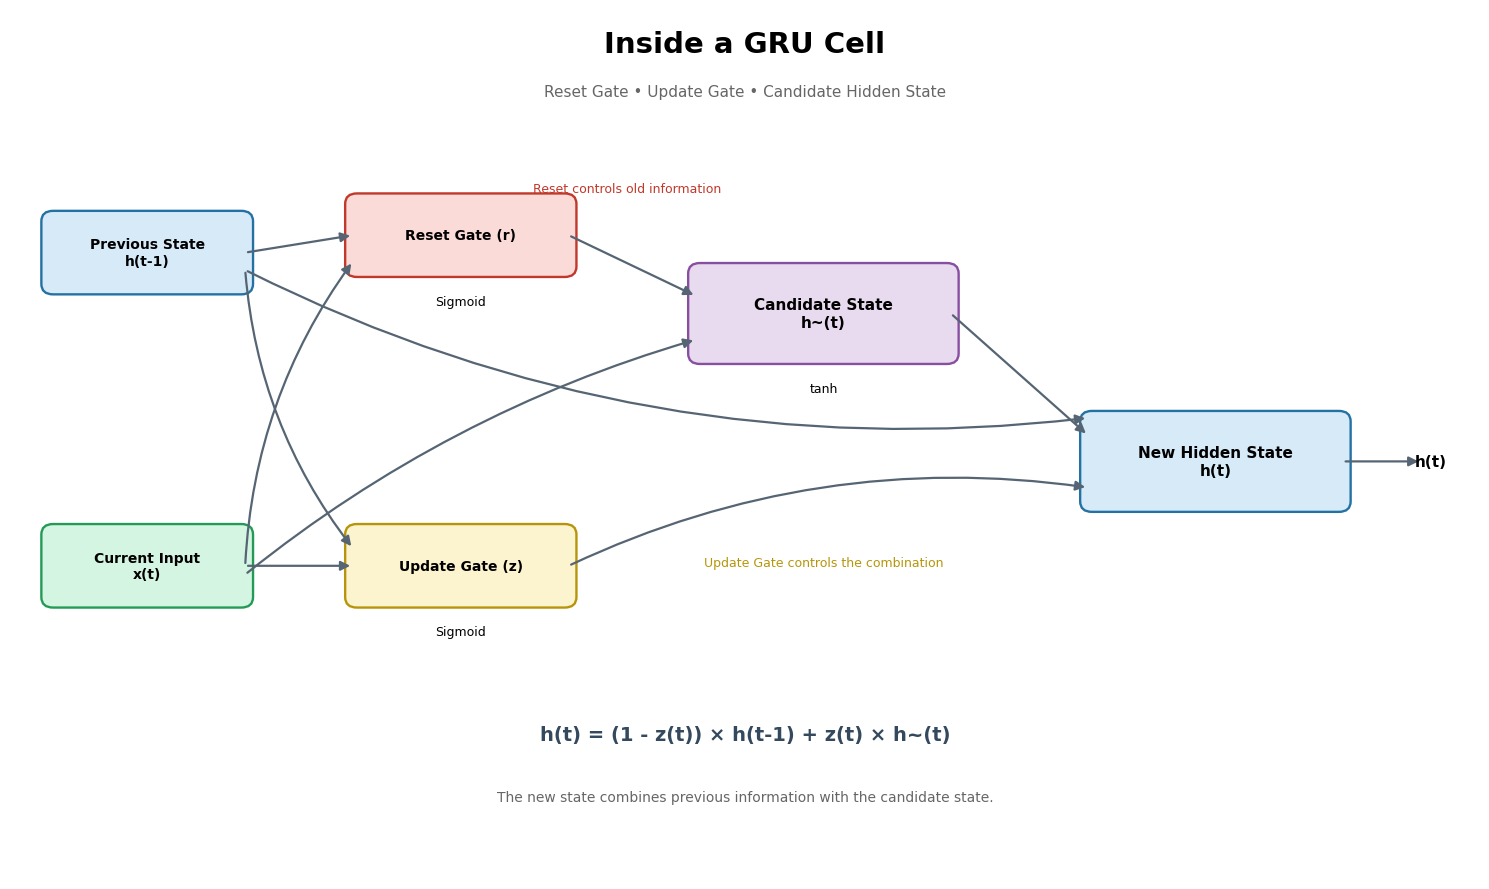

In [97]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ==========================================
# 1. Setup
# ==========================================

fig, ax = plt.subplots(figsize=(15, 9))

ax.set_xlim(0, 15)
ax.set_ylim(0, 10)
ax.axis("off")


def box(x, y, w, h, label, color, edge, fs=10):

    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        facecolor=color,
        edgecolor=edge,
        linewidth=1.7
    )
    ax.add_patch(patch)

    ax.text(
        x + w/2, y + h/2,
        label,
        ha="center", va="center",
        fontsize=fs, fontweight="bold"
    )


def arrow(x1, y1, x2, y2, color="#566573",
          rad=0, style="-"):

    ax.add_patch(
        FancyArrowPatch(
            (x1, y1), (x2, y2),
            arrowstyle="-|>",
            mutation_scale=14,
            linewidth=1.6,
            color=color,
            linestyle=style,
            connectionstyle=f"arc3,rad={rad}"
        )
    )


# ==========================================
# 2. Title
# ==========================================

ax.text(
    7.5, 9.5,
    "Inside a GRU Cell",
    ha="center",
    fontsize=21,
    fontweight="bold"
)

ax.text(
    7.5, 9.0,
    "Reset Gate • Update Gate • Candidate Hidden State",
    ha="center",
    fontsize=11,
    color="#666666"
)


# ==========================================
# 3. Inputs
# ==========================================

box(0.4, 6.8, 2.0, 0.8,
    "Previous State\nh(t-1)",
    "#D6EAF8", "#2471A3")

box(0.4, 3.2, 2.0, 0.8,
    "Current Input\nx(t)",
    "#D5F5E3", "#239B56")


# ==========================================
# 4. Reset Gate
# ==========================================

box(3.5, 7.0, 2.2, 0.8,
    "Reset Gate (r)",
    "#FADBD8", "#C0392B")

ax.text(
    4.6, 6.6,
    "Sigmoid",
    ha="center", fontsize=9
)

arrow(2.4, 7.2, 3.5, 7.4)
arrow(2.4, 3.6, 3.5, 7.1, rad=-0.15)

# ==========================================
# 5. Update Gate
# ==========================================

box(3.5, 3.2, 2.2, 0.8,
    "Update Gate (z)",
    "#FCF3CF", "#B7950B")

ax.text(
    4.6, 2.8,
    "Sigmoid",
    ha="center", fontsize=9
)

arrow(2.4, 7.0, 3.5, 3.8, rad=0.15)
arrow(2.4, 3.6, 3.5, 3.6)

# ==========================================
# 6. Candidate Hidden State
# ==========================================

box(7.0, 6.0, 2.6, 1.0,
    "Candidate State\nh~(t)",
    "#E8DAEF", "#884EA0", 11)

ax.text(
    8.3, 5.6,
    "tanh",
    ha="center", fontsize=9
)

arrow(5.7, 7.4, 7.0, 6.7)
arrow(2.4, 3.5, 7.0, 6.2, rad=-0.1)

# Reset gate controls previous-state contribution
ax.text(
    6.3, 7.9,
    "Reset controls old information",
    ha="center", fontsize=9, color="#C0392B"
)

# ==========================================
# 7. Final Hidden State
# ==========================================

box(11.0, 4.3, 2.6, 1.0,
    "New Hidden State\nh(t)",
    "#D6EAF8", "#2471A3", 11)

# Update gate and previous state feed into final update
arrow(5.7, 3.6, 11.0, 4.5, rad=-0.15)
arrow(9.6, 6.5, 11.0, 5.1)
arrow(2.4, 7.0, 11.0, 5.3, rad=0.15)

ax.text(
    8.3, 3.6,
    "Update Gate controls the combination",
    ha="center", fontsize=9, color="#B7950B"
)

# ==========================================
# 8. Output
# ==========================================

arrow(13.6, 4.8, 14.4, 4.8)

ax.text(
    14.5, 4.8,
    "h(t)",
    ha="center", va="center",
    fontsize=11, fontweight="bold"
)

# ==========================================
# 9. Formula
# ==========================================

ax.text(
    7.5, 1.6,
    "h(t) = (1 - z(t)) × h(t-1) + z(t) × h~(t)",
    ha="center",
    fontsize=14,
    fontweight="bold",
    color="#34495E"
)

ax.text(
    7.5, 0.9,
    "The new state combines previous information with the candidate state.",
    ha="center",
    fontsize=10,
    color="#666666"
)

plt.tight_layout()
plt.show()


In [48]:

model = Sequential([
    layers.Input(shape=(200,)),
    layers.Embedding(input_dim=10000, output_dim=64, mask_zero=True),
    layers.GRU(64),
    layers.Dropout(0.4),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [49]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 666,017 (2.54 MB)

 Trainable params: 666,017 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

test_loss, test_acc = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.7002 - loss: 0.5654 - val_accuracy: 0.8342 - val_loss: 0.3965
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8701 - loss: 0.3279 - val_accuracy: 0.8546 - val_loss: 0.3596
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9121 - loss: 0.2448 - val_accuracy: 0.8738 - val_loss: 0.3373
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9373 - loss: 0.1805 - val_accuracy: 0.8618 - val_loss: 0.3778
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9568 - loss: 0.1321 - val_accuracy: 0.8728 - val_loss: 0.4156
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9690 - loss: 0.0935 - val_accuracy: 0.8674 - val_loss: 0.5106
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9830 - loss: 0.0542 - val_accuracy: 0.8612 - val_loss: 0.5736
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9901 - loss: 0.0341 - val_ac

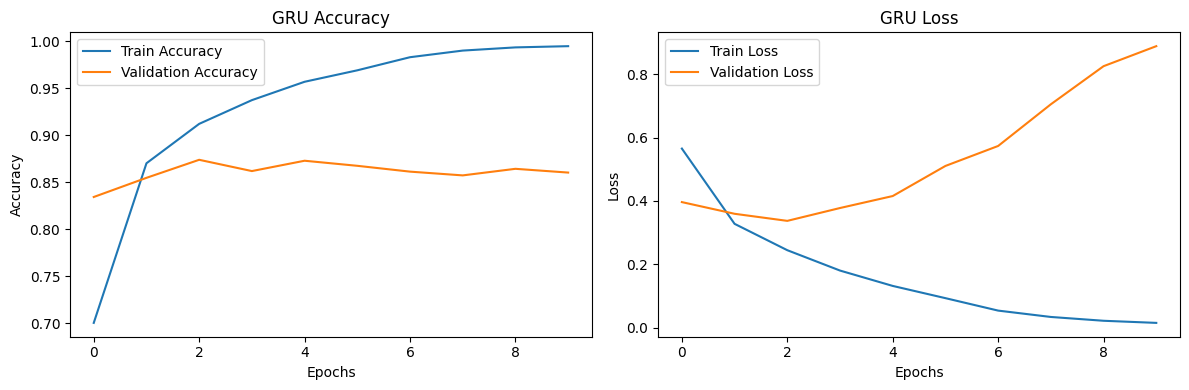

In [51]:


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("GRU Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("GRU Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

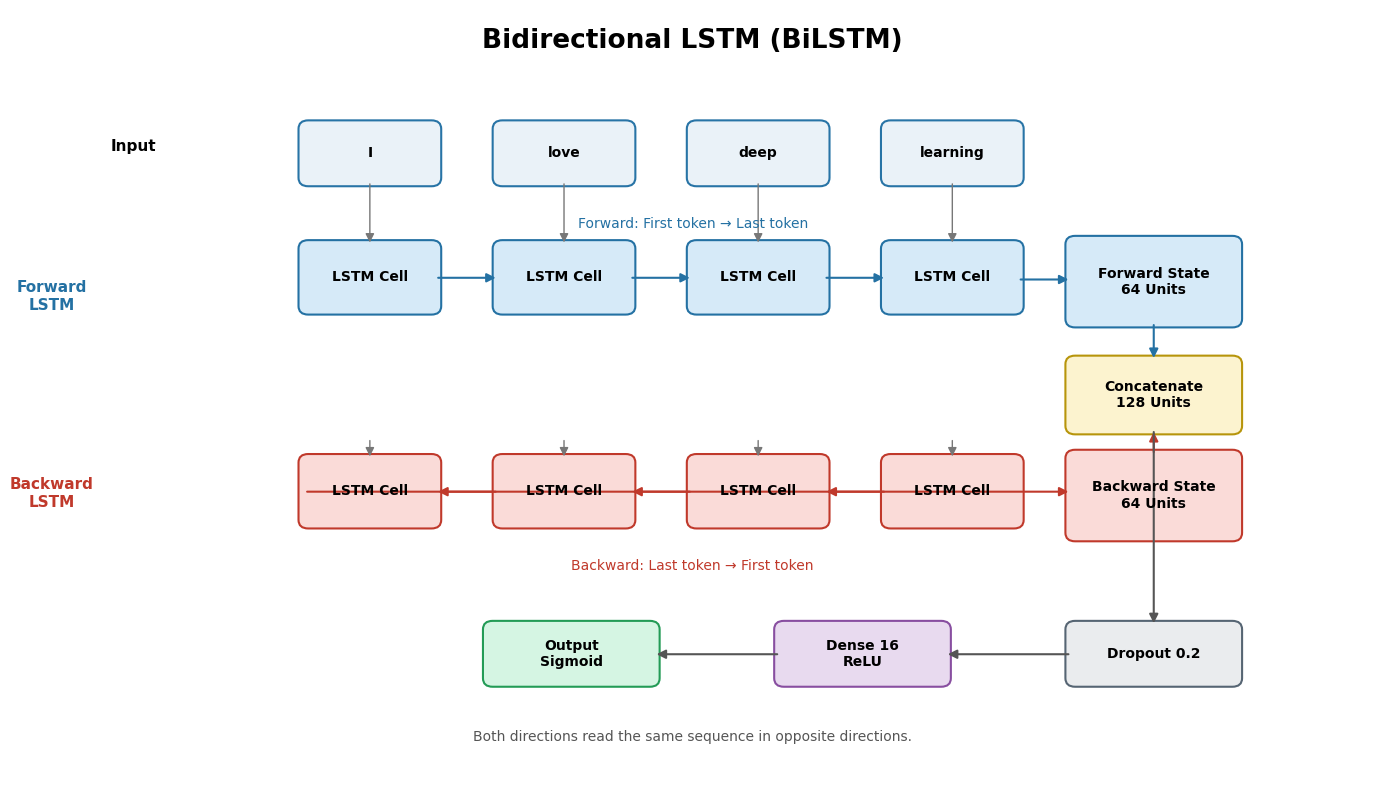

In [101]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(14, 8))
ax.set_xlim(0, 14)
ax.set_ylim(0, 9)
ax.axis("off")


def box(x, y, w, h, label, color, edge, fs=10):
    p = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.06,rounding_size=0.1",
        facecolor=color,
        edgecolor=edge,
        linewidth=1.5
    )
    ax.add_patch(p)
    ax.text(
        x + w/2, y + h/2, label,
        ha="center", va="center",
        fontsize=fs, fontweight="bold"
    )


def arrow(x1, y1, x2, y2, color="#555555", lw=1.5):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=13,
        linewidth=lw,
        color=color
    ))


# Title
ax.text(
    7, 8.55, "Bidirectional LSTM (BiLSTM)",
    ha="center", fontsize=19, fontweight="bold"
)

# Input sequence
words = ["I", "love", "deep", "learning"]
xs = [3.0, 5.0, 7.0, 9.0]

ax.text(1.0, 7.35, "Input", fontsize=11, fontweight="bold")

for x, word in zip(xs, words):
    box(x, 7.0, 1.35, 0.65, word, "#EAF2F8", "#2874A6")

# Forward direction
ax.text(
    0.4, 5.65, "Forward\nLSTM",
    ha="center", va="center",
    fontsize=11, fontweight="bold", color="#2471A3"
)

forward_y = 5.5

for x in xs:
    box(x, forward_y, 1.35, 0.75,
        "LSTM Cell", "#D6EAF8", "#2471A3")

for i in range(3):
    arrow(
        xs[i] + 1.35, forward_y + 0.37,
        xs[i+1], forward_y + 0.37,
        "#2471A3"
    )

ax.text(
    7, 6.45, "Forward: First token → Last token",
    ha="center", fontsize=10, color="#2471A3"
)

# Backward direction
ax.text(
    0.4, 3.35, "Backward\nLSTM",
    ha="center", va="center",
    fontsize=11, fontweight="bold", color="#C0392B"
)

backward_y = 3.0

for x in xs:
    box(x, backward_y, 1.35, 0.75,
        "LSTM Cell", "#FADBD8", "#C0392B")

for i in range(3):
    arrow(
        xs[i+1], backward_y + 0.37,
        xs[i] + 1.35, backward_y + 0.37,
        "#C0392B"
    )

ax.text(
    7, 2.45, "Backward: Last token → First token",
    ha="center", fontsize=10, color="#C0392B"
)

# Input sequence connections to both directions
for x in xs:
    arrow(x + 0.675, 7.0, x + 0.675, 6.25, "#777777", 1.0)
    arrow(x + 0.675, 4.0, x + 0.675, 3.75, "#777777", 1.0)

# Final states from opposite ends
box(10.9, 5.35, 1.7, 0.95,
    "Forward State\n64 Units", "#D6EAF8", "#2471A3")

box(10.9, 2.85, 1.7, 0.95,
    "Backward State\n64 Units", "#FADBD8", "#C0392B")

arrow(10.35, 5.85, 10.9, 5.85, "#2471A3")
arrow(3.0, 3.37, 10.9, 3.37, "#C0392B")

# Concatenation
box(10.9, 4.1, 1.7, 0.8,
    "Concatenate\n128 Units", "#FCF3CF", "#B7950B")

arrow(11.75, 5.35, 11.75, 4.9, "#2471A3")
arrow(11.75, 3.8, 11.75, 4.1, "#C0392B")

# Classification layers
box(10.9, 1.15, 1.7, 0.65,
    "Dropout 0.2", "#EAECEE", "#566573")

box(7.9, 1.15, 1.7, 0.65,
    "Dense 16\nReLU", "#E8DAEF", "#884EA0")

box(4.9, 1.15, 1.7, 0.65,
    "Output\nSigmoid", "#D5F5E3", "#239B56")

arrow(11.75, 4.1, 11.75, 1.8)
arrow(10.9, 1.47, 9.6, 1.47)
arrow(7.9, 1.47, 6.6, 1.47)

ax.text(
    7, 0.45,
    "Both directions read the same sequence in opposite directions.",
    ha="center", fontsize=10, color="#555555"
)

plt.tight_layout()
plt.show()


In [51]:
model = Sequential([
    layers.Input(shape=(200,)),

    layers.Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),

    layers.Bidirectional(
        layers.LSTM(64)
    ),

    layers.Dropout(0.2),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

In [51]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

In [52]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9959 - loss: 0.0118 - val_accuracy: 0.8602 - val_loss: 0.9450
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9988 - loss: 0.0038 - val_accuracy: 0.8604 - val_loss: 1.0077
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9993 - loss: 0.0023 - val_accuracy: 0.8638 - val_loss: 1.0664
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9997 - loss: 0.0010 - val_accuracy: 0.8608 - val_loss: 1.1860
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 1.0000 - loss: 2.6587e-04 - val_accuracy: 0.8588 - val_loss: 1.2560


In [53]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8302 - loss: 1.5274
Test Loss: 1.5273576974868774
Test Accuracy: 0.83024001121521


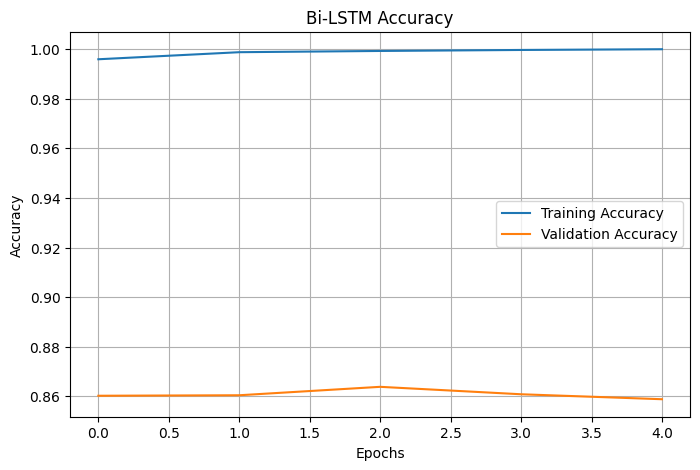

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Bi-LSTM Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

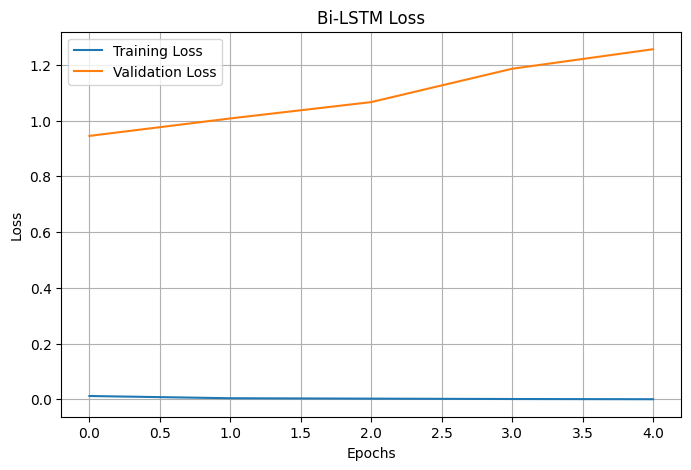

In [55]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Bi-LSTM Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

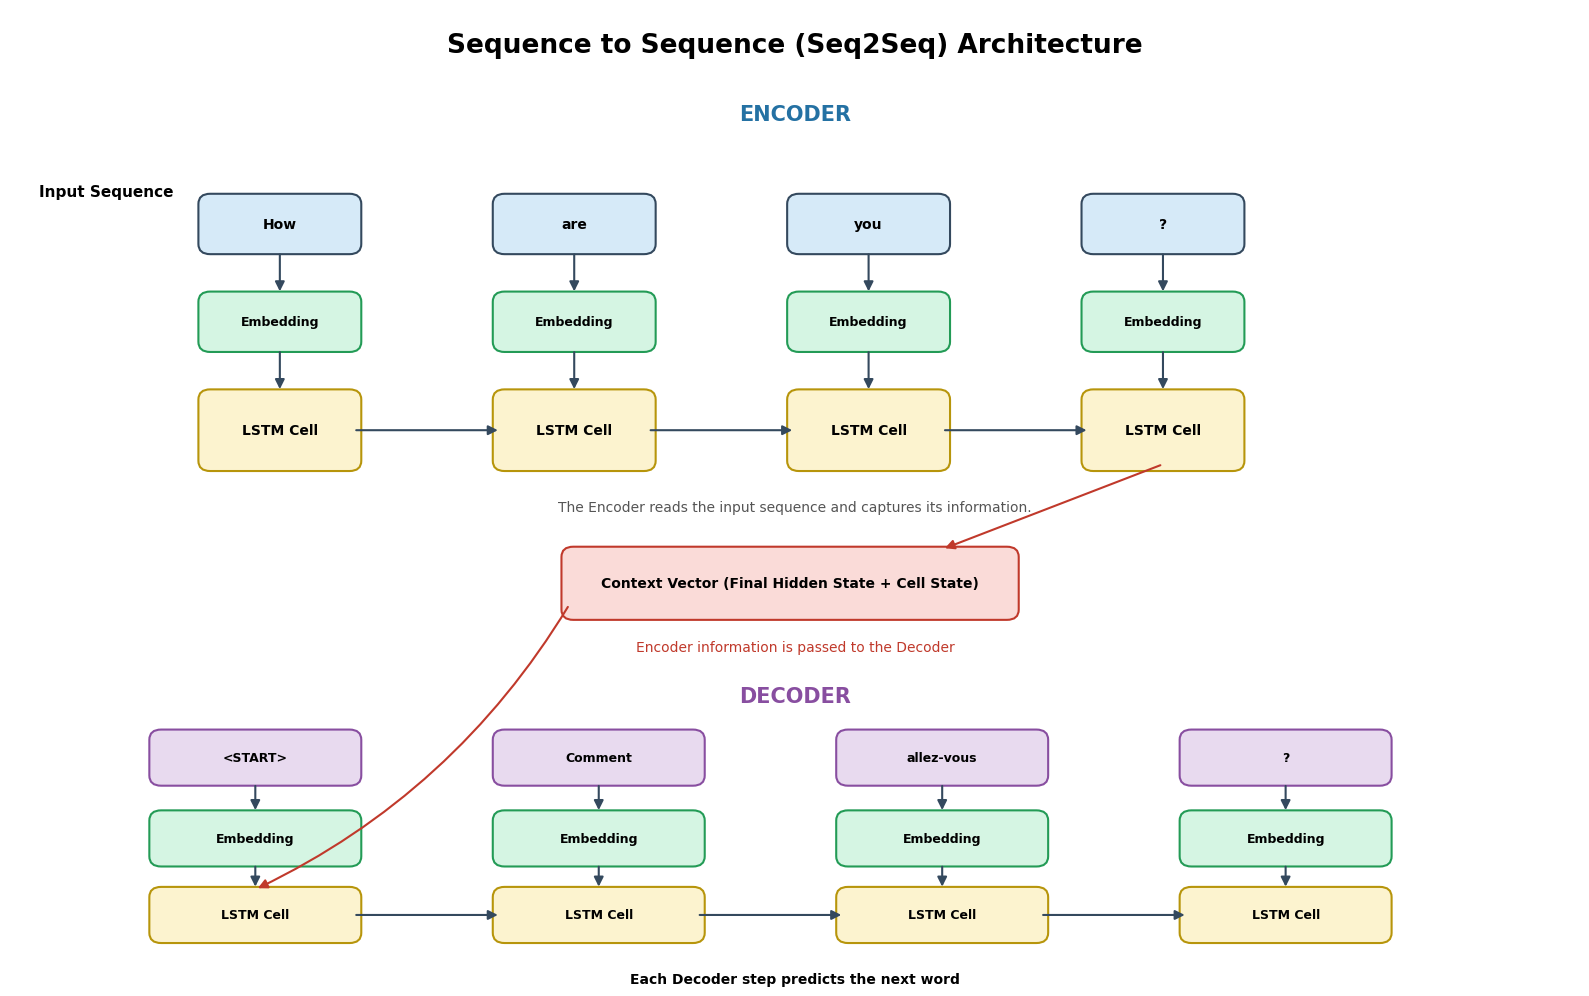

In [89]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ==========================================
# 1. Drawing Functions
# ==========================================

fig, ax = plt.subplots(figsize=(16, 10))

ax.set_xlim(0, 16)
ax.set_ylim(0, 11)
ax.axis("off")


def draw_box(x, y, width, height, text,
             color="#EAF2F8", edge="#34495E",
             fontsize=10, radius=0.12):

    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle=f"round,pad=0.08,rounding_size={radius}",
        facecolor=color,
        edgecolor=edge,
        linewidth=1.5
    )

    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight="bold"
    )


def draw_arrow(x1, y1, x2, y2,
               color="#34495E", style="-",
               rad=0):

    arrow = FancyArrowPatch(
        (x1, y1),
        (x2, y2),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=1.5,
        color=color,
        linestyle=style,
        connectionstyle=f"arc3,rad={rad}"
    )

    ax.add_patch(arrow)


# ==========================================
# 2. Main Title
# ==========================================

ax.text(
    8, 10.5,
    "Sequence to Sequence (Seq2Seq) Architecture",
    ha="center",
    fontsize=19,
    fontweight="bold"
)

# ==========================================
# 3. Encoder
# ==========================================

ax.text(
    8, 9.7,
    "ENCODER",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color="#2471A3"
)

ax.text(
    0.3, 8.8,
    "Input Sequence",
    fontsize=11,
    fontweight="bold"
)

encoder_words = ["How", "are", "you", "?"]

x_positions = [2, 5, 8, 11]

for x, word in zip(x_positions, encoder_words):

    # Input word
    draw_box(
        x, 8.2, 1.5, 0.55,
        word,
        color="#D6EAF8"
    )

    # Embedding
    draw_arrow(x + 0.75, 8.15, x + 0.75, 7.65)

    draw_box(
        x, 7.05, 1.5, 0.55,
        "Embedding",
        color="#D5F5E3",
        edge="#239B56",
        fontsize=9
    )

    # LSTM
    draw_arrow(x + 0.75, 7.0, x + 0.75, 6.5)

    draw_box(
        x, 5.65, 1.5, 0.8,
        "LSTM Cell",
        color="#FCF3CF",
        edge="#B7950B"
    )

# Connect encoder LSTM cells
for i in range(3):
    draw_arrow(
        x_positions[i] + 1.5, 6.05,
        x_positions[i + 1], 6.05
    )

# Encoder description
ax.text(
    8, 5.1,
    "The Encoder reads the input sequence and captures its information.",
    ha="center",
    fontsize=10,
    color="#555555"
)

# ==========================================
# 4. Context Vector
# ==========================================

draw_box(
    5.7, 3.9, 4.5, 0.7,
    "Context Vector (Final Hidden State + Cell State)",
    color="#FADBD8",
    edge="#C0392B",
    fontsize=10
)

draw_arrow(11.75, 5.65, 9.5, 4.65, color="#C0392B")

ax.text(
    8, 3.45,
    "Encoder information is passed to the Decoder",
    ha="center",
    fontsize=10,
    color="#C0392B"
)

# ==========================================
# 5. Decoder
# ==========================================

ax.text(
    8, 2.85,
    "DECODER",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color="#884EA0"
)

decoder_inputs = ["<START>", "Comment", "allez-vous", "?"]
decoder_outputs = ["Comment", "allez-vous", "?", "<END>"]

decoder_x = [1.5, 5, 8.5, 12]

for i, x in enumerate(decoder_x):

    # Decoder input
    draw_box(
        x, 1.95, 2, 0.5,
        decoder_inputs[i],
        color="#E8DAEF",
        edge="#884EA0",
        fontsize=9
    )

    # Embedding
    draw_arrow(x + 1, 1.9, x + 1, 1.55)

    draw_box(
        x, 1.0, 2, 0.5,
        "Embedding",
        color="#D5F5E3",
        edge="#239B56",
        fontsize=9
    )

    # LSTM
    draw_arrow(x + 1, 0.95, x + 1, 0.65)

    draw_box(
        x, 0.1, 2, 0.5,
        "LSTM Cell",
        color="#FCF3CF",
        edge="#B7950B",
        fontsize=9
    )

# Connect decoder LSTM cells
for i in range(3):
    draw_arrow(
        decoder_x[i] + 2, 0.35,
        decoder_x[i + 1], 0.35
    )

# Context to first decoder cell
draw_arrow(
    5.7, 4.0,
    2.5, 0.65,
    color="#C0392B",
    rad=-0.15
)

# ==========================================
# 6. Decoder Output (shown separately)
# ==========================================

ax.text(
    8, -0.45,
    "Each Decoder step predicts the next word",
    ha="center",
    fontsize=10,
    fontweight="bold"
)

# ==========================================
# 7. Display
# ==========================================

plt.tight_layout()
plt.show()


In [59]:
import numpy as np
import keras
from keras import layers
import requests
import zipfile
import os

In [60]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip"

response = requests.get(url)
response.raise_for_status()

with open("fra-eng.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("fra-eng.zip", "r") as z:
    z.extractall("fra_data")

data_path = "fra_data/fra.txt"

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [61]:
batch_size = 64
epochs = 20
latent_dim = 128
num_samples = 10000

In [62]:
input_texts = []
target_texts = []

input_characters = set()
target_characters = set()

with open(data_path, encoding="utf-8") as f:
    lines = f.read().split("\n")

for line in lines[:num_samples]:

    parts = line.split("\t")

    if len(parts) < 2:
        continue

    input_text = parts[0]
    target_text = "\t" + parts[1] + "\n"

    input_texts.append(input_text)
    target_texts.append(target_text)

    input_characters.update(input_text)
    target_characters.update(target_text)

In [63]:
input_characters = sorted(list(input_characters))
target_characters = sorted(list(target_characters))

num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)

max_encoder_seq_length = max(
    len(txt) for txt in input_texts
)

max_decoder_seq_length = max(
    len(txt) for txt in target_texts
)

input_token_index = {
    char: i for i, char in enumerate(input_characters)
}

target_token_index = {
    char: i for i, char in enumerate(target_characters)
}

print("Number of samples:", len(input_texts))
print("Encoder Tokens:", num_encoder_tokens)
print("Decoder Tokens:", num_decoder_tokens)
print("Max Encoder Length:", max_encoder_seq_length)
print("Max Decoder Length:", max_decoder_seq_length)

Number of samples: 10000
Encoder Tokens: 70
Decoder Tokens: 93
Max Encoder Length: 16
Max Decoder Length: 59


In [64]:
encoder_input_data = np.zeros(
    (len(input_texts), max_encoder_seq_length, num_encoder_tokens),
    dtype="float32"
)

decoder_input_data = np.zeros(
    (len(input_texts), max_decoder_seq_length, num_decoder_tokens),
    dtype="float32"
)

decoder_target_data = np.zeros(
    (len(input_texts), max_decoder_seq_length, num_decoder_tokens),
    dtype="float32"
)

In [65]:
for i, (input_text, target_text) in enumerate(
    zip(input_texts, target_texts)
):

    for t, char in enumerate(input_text):
        encoder_input_data[i, t, input_token_index[char]] = 1.0

    encoder_input_data[
        i, t + 1:, input_token_index[" "]
    ] = 1.0

    for t, char in enumerate(target_text):

        decoder_input_data[
            i, t, target_token_index[char]
        ] = 1.0

        if t > 0:
            decoder_target_data[
                i, t - 1, target_token_index[char]
            ] = 1.0

    decoder_input_data[
        i, t + 1:, target_token_index[" "]
    ] = 1.0

    decoder_target_data[
        i, t:, target_token_index[" "]
    ] = 1.0

In [66]:
# Encoder
encoder_inputs = keras.Input(
    shape=(None, num_encoder_tokens)
)

encoder = layers.LSTM(
    latent_dim,
    return_state=True
)

_, state_h, state_c = encoder(encoder_inputs)

encoder_states = [state_h, state_c]


# Decoder
decoder_inputs = keras.Input(
    shape=(None, num_decoder_tokens)
)

decoder_lstm = layers.LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_inputs,
    initial_state=encoder_states
)


# Output
decoder_dense = layers.Dense(
    num_decoder_tokens,
    activation="softmax"
)

decoder_outputs = decoder_dense(decoder_outputs)


# Model
model = keras.Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, None, 70)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_6       │ (None, None, 93)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 128),     │    101,888 │ input_layer_5[0]… │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, None,     │    113,664 │ input_layer_6[0]… │
│                     │ 128), (None,      │            │ lstm_1[0][1],     │
│                     │ 128), (None,      │            │ lstm_1[0][2]      │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, None, 93)  │     11,997 │ lstm_2[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 227,549 (888.86 KB)

 Trainable params: 227,549 (888.86 KB)

 Non-trainable params: 0 (0.00 B)

In [67]:
model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [78]:
history = model.fit(
    [encoder_input_data, decoder_input_data],
    decoder_target_data,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2
)

Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9077 - loss: 0.3100 - val_accuracy: 0.8680 - val_loss: 0.4659
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9077 - loss: 0.3089 - val_accuracy: 0.8676 - val_loss: 0.4663
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9086 - loss: 0.3069 - val_accuracy: 0.8678 - val_loss: 0.4668
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9091 - loss: 0.3053 - val_accuracy: 0.8676 - val_loss: 0.4665
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9095 - loss: 0.3038 - val_accuracy: 0.8684 - val_loss: 0.4653
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9099 - loss: 0.3022 - val_accuracy: 0.8677 - val_loss: 0.4665
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9105 - loss: 0.3007 - val_accuracy: 0.8682 - val_loss: 0.4665
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9111 - loss: 0.2990 - val_accu

In [79]:
model.save("seq2seq_model.keras")

In [80]:
encoder_model = keras.Model(
    encoder_inputs,
    encoder_states
)

In [81]:
decoder_state_input_h = keras.Input(
    shape=(latent_dim,)
)

decoder_state_input_c = keras.Input(
    shape=(latent_dim,)
)

decoder_states_inputs = [
    decoder_state_input_h,
    decoder_state_input_c
]

decoder_outputs, state_h_dec, state_c_dec = decoder_lstm(
    decoder_inputs,
    initial_state=decoder_states_inputs
)

decoder_states = [state_h_dec, state_c_dec]

decoder_outputs = decoder_dense(decoder_outputs)

decoder_model = keras.Model(
    [decoder_inputs] + decoder_states_inputs,
    [decoder_outputs] + decoder_states
)

In [82]:
reverse_target_char_index = {
    i: char for char, i in target_token_index.items()
}

In [83]:
def decode_sequence(input_seq):

    states_value = encoder_model.predict(
        input_seq,
        verbose=0
    )

    target_seq = np.zeros(
        (1, 1, num_decoder_tokens)
    )

    target_seq[0, 0, target_token_index["\t"]] = 1.0

    decoded_sentence = ""

    for _ in range(max_decoder_seq_length):

        output_tokens, h, c = decoder_model.predict(
            [target_seq] + states_value,
            verbose=0
        )

        sampled_index = np.argmax(
            output_tokens[0, -1, :]
        )

        sampled_char = reverse_target_char_index[sampled_index]

        if sampled_char == "\n":
            break

        decoded_sentence += sampled_char

        target_seq = np.zeros(
            (1, 1, num_decoder_tokens)
        )

        target_seq[0, 0, sampled_index] = 1.0

        states_value = [h, c]

    return decoded_sentence

In [84]:
for i in range(20):

    input_seq = encoder_input_data[i:i+1]

    decoded_sentence = decode_sequence(input_seq)

    print("Input:", input_texts[i])
    print("Actual:", target_texts[i][1:-1])
    print("Predicted:", decoded_sentence)

    print("-" * 40)

Input: Go.
Actual: Va !
Predicted: Va voir !
----------------------------------------
Input: Hi.
Actual: Salut !
Predicted: Collant !
----------------------------------------
Input: Run!
Actual: Cours !
Predicted: Prends un bouss !
----------------------------------------
Input: Run!
Actual: Courez !
Predicted: Prends un bouss !
----------------------------------------
Input: Who?
Actual: Qui ?
Predicted: Qui est allessée ?
----------------------------------------
Input: Wow!
Actual: Ça alors !
Predicted: Fait-ce avec moi.
----------------------------------------
Input: Fire!
Actual: Au feu !
Predicted: Prends-le l'aissoir !
----------------------------------------
Input: Help!
Actual: À l'aide !
Predicted: Assez-vous !
----------------------------------------
Input: Jump.
Actual: Saute.
Predicted: Regarde !
----------------------------------------
Input: Stop!
Actual: Ça suffit !
Predicted: Regarde !
----------------------------------------
Input: Stop!
Actual: Stop !
Predicted: Regar

In [106]:

# ==========================================
# 1. Encoder
# ==========================================

encoder_inputs = keras.Input(
    shape=(None, num_encoder_tokens)
)

encoder_lstm = layers.LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

encoder_outputs, state_h, state_c = encoder_lstm(
    encoder_inputs
)

encoder_states = [state_h, state_c]


# ==========================================
# 2. Decoder
# ==========================================

decoder_inputs = keras.Input(
    shape=(None, num_decoder_tokens)
)

decoder_lstm = layers.LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_inputs,
    initial_state=encoder_states
)


# ==========================================
# 3. Attention Mechanism
# ==========================================

attention_layer = layers.AdditiveAttention(
    name="attention"
)

context_vector = attention_layer(
    [decoder_outputs, encoder_outputs]
)


# ==========================================
# 4. Combine Decoder + Context
# ==========================================

decoder_combined = layers.Concatenate(
    axis=-1
)([decoder_outputs, context_vector])


# ==========================================
# 5. Output Layer
# ==========================================

decoder_dense = layers.Dense(
    num_decoder_tokens,
    activation="softmax"
)

decoder_outputs = decoder_dense(
    decoder_combined
)


# ==========================================
# 6. Build Model
# ==========================================

model = keras.Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.summary()


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, None, 70)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_14      │ (None, None, 93)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_5 (LSTM)       │ [(None, None,     │    101,888 │ input_layer_13[0… │
│                     │ 128), (None,      │            │                   │
│                     │ 128), (None,      │            │                   │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_6 (LSTM)       │ [(None, None,     │    113,664 │ input_layer_14[0… │
│                     │ 128), (None,      │            │ lstm_5[0][1],     │
│                     │ 128), (None,      │            │ lstm_5[0][2]      │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, None, 128) │        128 │ lstm_6[0][0],     │
│ (AdditiveAttention) │                   │            │ lstm_5[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, None, 256) │          0 │ lstm_6[0][0],     │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, None, 93)  │     23,901 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 239,581 (935.86 KB)

 Trainable params: 239,581 (935.86 KB)

 Non-trainable params: 0 (0.00 B)

In [110]:

model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    [encoder_input_data, decoder_input_data],
    decoder_target_data,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2
)

model.save("seq2seq_attention_model.keras")


Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9062 - loss: 0.3144 - val_accuracy: 0.8646 - val_loss: 0.4712
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9072 - loss: 0.3111 - val_accuracy: 0.8648 - val_loss: 0.4709
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9079 - loss: 0.3088 - val_accuracy: 0.8650 - val_loss: 0.4709
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9086 - loss: 0.3068 - val_accuracy: 0.8643 - val_loss: 0.4724
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9094 - loss: 0.3046 - val_accuracy: 0.8648 - val_loss: 0.4707
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9097 - loss: 0.3027 - val_accuracy: 0.8648 - val_loss: 0.4724
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9104 - loss: 0.3006 - val_accuracy: 0.8651 - val_loss: 0.4718
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9111 - loss: 0.2985 - val_accu

In [111]:

# ==========================================
# 1. Encoder Inference Model
# ==========================================

encoder_model = keras.Model(
    encoder_inputs,
    [encoder_outputs, state_h, state_c]
)


# ==========================================
# 2. Decoder State Inputs
# ==========================================

decoder_state_input_h = keras.Input(
    shape=(latent_dim,)
)

decoder_state_input_c = keras.Input(
    shape=(latent_dim,)
)

decoder_states_inputs = [
    decoder_state_input_h,
    decoder_state_input_c
]


# ==========================================
# 3. Encoder Outputs Input
# ==========================================

encoder_outputs_input = keras.Input(
    shape=(None, latent_dim)
)


# ==========================================
# 4. Decoder One-Step
# ==========================================

decoder_outputs, state_h_dec, state_c_dec = decoder_lstm(
    decoder_inputs,
    initial_state=decoder_states_inputs
)

decoder_states = [
    state_h_dec,
    state_c_dec
]


# ==========================================
# 5. Attention
# ==========================================

context_vector, attention_weights = attention_layer(
    [decoder_outputs, encoder_outputs_input],
    return_attention_scores=True
)


# ==========================================
# 6. Combine
# ==========================================

decoder_combined = layers.Concatenate(
    axis=-1
)([decoder_outputs, context_vector])


# ==========================================
# 7. Output
# ==========================================

decoder_outputs = decoder_dense(
    decoder_combined
)


# ==========================================
# 8. Decoder Model
# ==========================================

decoder_model = keras.Model(
    [decoder_inputs]
    + decoder_states_inputs
    + [encoder_outputs_input],

    [decoder_outputs]
    + decoder_states
    + [attention_weights]
)


In [112]:

reverse_target_char_index = {
    i: char
    for char, i in target_token_index.items()
}


def decode_sequence(input_seq):

    # Get Encoder Outputs and States
    encoder_output, state_h, state_c = encoder_model.predict(
        input_seq,
        verbose=0
    )

    states_value = [state_h, state_c]

    # Start Token
    target_seq = np.zeros(
        (1, 1, num_decoder_tokens)
    )

    target_seq[0, 0, target_token_index["\t"]] = 1.0

    decoded_sentence = ""

    attention_history = []

    for _ in range(max_decoder_seq_length):

        # Decoder Prediction
        output_tokens, h, c, attention_weights = decoder_model.predict(
            [target_seq] + states_value + [encoder_output],
            verbose=0
        )

        # Get Predicted Character
        sampled_index = np.argmax(
            output_tokens[0, -1, :]
        )

        sampled_char = reverse_target_char_index[sampled_index]

        # Stop at End Token
        if sampled_char == "\n":
            break

        decoded_sentence += sampled_char

        # Save Attention Weights
        attention_history.append(
            attention_weights[0, 0, :]
        )

        # Next Decoder Input
        target_seq = np.zeros(
            (1, 1, num_decoder_tokens)
        )

        target_seq[0, 0, sampled_index] = 1.0

        # Update States
        states_value = [h, c]

    return decoded_sentence, np.array(attention_history)


In [113]:

for i in range(20):

    input_seq = encoder_input_data[i:i+1]

    predicted, attention_weights = decode_sequence(input_seq)

    print("Input:    ", input_texts[i])
    print("Actual:   ", target_texts[i][1:-1])
    print("Predicted:", predicted)

    print("-" * 40)


Input:     Go.
Actual:    Va !
Predicted: Allez-vous !
----------------------------------------
Input:     Hi.
Actual:    Salut !
Predicted: Comment est-il !
----------------------------------------
Input:     Run!
Actual:    Cours !
Predicted: Laisse-moi !
----------------------------------------
Input:     Run!
Actual:    Courez !
Predicted: Laisse-moi !
----------------------------------------
Input:     Who?
Actual:    Qui ?
Predicted: Qui est-il ?
----------------------------------------
Input:     Wow!
Actual:    Ça alors !
Predicted: Fait-ce que ça ?
----------------------------------------
Input:     Fire!
Actual:    Au feu !
Predicted: La vie !
----------------------------------------
Input:     Help!
Actual:    À l'aide !
Predicted: Lar !
----------------------------------------
Input:     Jump.
Actual:    Saute.
Predicted: Laisse-toi !
----------------------------------------
Input:     Stop!
Actual:    Ça suffit !
Predicted: Attends-nous !
----------------------------------

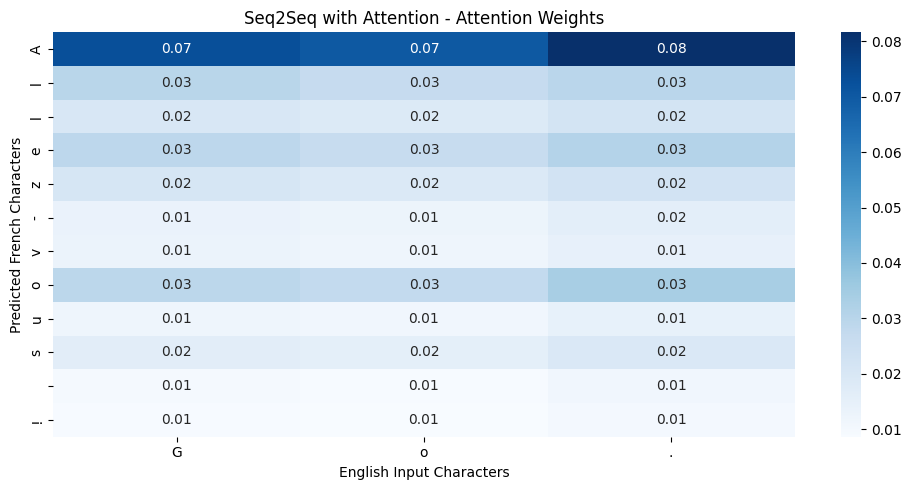

Input:     Go.
Predicted: Allez-vous !


In [114]:

import matplotlib.pyplot as plt
import seaborn as sns

# Choose one example
i = 0

input_seq = encoder_input_data[i:i+1]

predicted, attention_weights = decode_sequence(input_seq)

# Characters
source_chars = list(input_texts[i])
target_chars = list(predicted)

# Plot
plt.figure(figsize=(10, 5))

sns.heatmap(
    attention_weights[:, :len(source_chars)],
    xticklabels=source_chars,
    yticklabels=target_chars,
    cmap="Blues",
    annot=True,
    fmt=".2f"
)

plt.xlabel("English Input Characters")
plt.ylabel("Predicted French Characters")

plt.title("Seq2Seq with Attention - Attention Weights")

plt.tight_layout()
plt.show()

print("Input:    ", input_texts[i])
print("Predicted:", predicted)


In [115]:
# Prepare English and French sentences

english_sentences = input_texts

french_sentences = [
    text[1:-1].lower()
    for text in target_texts
]

# Add Start and End Tokens

target_sentences = [
    "startseq " + text + " endseq"
    for text in french_sentences
]

# Calculate maximum lengths

max_encoder_length = max(
    len(text.split())
    for text in english_sentences
)

max_decoder_length = max(
    len(text.split())
    for text in target_sentences
)

print("Number of samples:", len(english_sentences))
print("Max English Length:", max_encoder_length)
print("Max French Length:", max_decoder_length)

Number of samples: 10000
Max English Length: 5
Max French Length: 12


In [116]:
# English Tokenizer

english_vectorizer = layers.TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=max_encoder_length
)

english_vectorizer.adapt(english_sentences)


# French Tokenizer

french_vectorizer = layers.TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=max_decoder_length
)

french_vectorizer.adapt(target_sentences)


# Vocabulary Sizes

english_vocab_size = len(
    english_vectorizer.get_vocabulary()
)

french_vocab_size = len(
    french_vectorizer.get_vocabulary()
)

print("English Vocabulary:", english_vocab_size)
print("French Vocabulary:", french_vocab_size)

English Vocabulary: 2138
French Vocabulary: 4845


In [118]:
# Convert sentences to token IDs

encoder_data = english_vectorizer(
    english_sentences
)

decoder_full = french_vectorizer(
    target_sentences
)

# Teacher Forcing

decoder_input_data = decoder_full[:, :-1]

decoder_target_data = decoder_full[:, 1:]

# Ignore Padding Tokens in the loss

sample_weights = tf.cast(
    tf.not_equal(decoder_target_data, 0),
    tf.float32
)

print("Encoder Shape:", encoder_data.shape)
print("Decoder Input Shape:", decoder_input_data.shape)
print("Decoder Target Shape:", decoder_target_data.shape)
print("Sample Weights Shape:", sample_weights.shape)

Encoder Shape: (10000, 5)
Decoder Input Shape: (10000, 11)
Decoder Target Shape: (10000, 11)
Sample Weights Shape: (10000, 11)


In [119]:
class PositionalEmbedding(layers.Layer):

    def __init__(self, vocab_size, sequence_length, embed_dim):
        super().__init__()

        self.token_embedding = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim,
            mask_zero=True
        )

        self.position_embedding = layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim
        )

    def call(self, inputs):

        length = keras.ops.shape(inputs)[-1]

        positions = keras.ops.arange(
            start=0,
            stop=length,
            step=1
        )

        token_vectors = self.token_embedding(inputs)

        position_vectors = self.position_embedding(positions)

        return token_vectors + position_vectors

In [120]:
class TransformerEncoder(layers.Layer):

    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.feed_forward = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()

        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)

    def call(self, inputs):

        x, padding_mask = inputs

        attention_mask = keras.ops.expand_dims(
            padding_mask, axis=1
        )

        attention_output = self.attention(
            query=x,
            value=x,
            key=x,
            attention_mask=attention_mask
        )

        x = self.norm1(
            x + self.dropout1(attention_output)
        )

        ff_output = self.feed_forward(x)

        x = self.norm2(
            x + self.dropout2(ff_output)
        )

        return x

In [121]:
class TransformerDecoder(layers.Layer):

    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1):
        super().__init__()

        self.self_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.cross_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.feed_forward = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()
        self.norm3 = layers.LayerNormalization()

        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)
        self.dropout3 = layers.Dropout(dropout)

    def call(self, inputs):

        x, encoder_output, decoder_mask, encoder_mask = inputs

        # Masked Self-Attention

        decoder_attention_mask = keras.ops.expand_dims(
            decoder_mask, axis=1
        )

        attention_output = self.self_attention(
            query=x,
            value=x,
            key=x,
            attention_mask=decoder_attention_mask,
            use_causal_mask=True
        )

        x = self.norm1(
            x + self.dropout1(attention_output)
        )

        # Cross-Attention

        encoder_attention_mask = keras.ops.expand_dims(
            encoder_mask, axis=1
        )

        cross_output = self.cross_attention(
            query=x,
            value=encoder_output,
            key=encoder_output,
            attention_mask=encoder_attention_mask
        )

        x = self.norm2(
            x + self.dropout2(cross_output)
        )

        # Feed Forward

        ff_output = self.feed_forward(x)

        x = self.norm3(
            x + self.dropout3(ff_output)
        )

        return x

In [122]:
# Model Parameters

embed_dim = 128
num_heads = 4
ff_dim = 256


# Encoder Input

encoder_inputs = keras.Input(
    shape=(max_encoder_length,),
    dtype="int64"
)

# Decoder Input

decoder_inputs = keras.Input(
    shape=(max_decoder_length - 1,),
    dtype="int64"
)


# Padding Masks

encoder_mask = keras.ops.not_equal(
    encoder_inputs, 0
)

decoder_mask = keras.ops.not_equal(
    decoder_inputs, 0
)


# Encoder Embedding

encoder_embedding = PositionalEmbedding(
    english_vocab_size,
    max_encoder_length,
    embed_dim
)(encoder_inputs)


# Encoder

encoder_output = TransformerEncoder(
    embed_dim,
    num_heads,
    ff_dim
)([encoder_embedding, encoder_mask])


# Decoder Embedding

decoder_embedding = PositionalEmbedding(
    french_vocab_size,
    max_decoder_length - 1,
    embed_dim
)(decoder_inputs)


# Decoder

decoder_output = TransformerDecoder(
    embed_dim,
    num_heads,
    ff_dim
)([
    decoder_embedding,
    encoder_output,
    decoder_mask,
    encoder_mask
])


# Output Layer

outputs = layers.Dense(
    french_vocab_size
)(decoder_output)


# Build Model

transformer = keras.Model(
    [encoder_inputs, decoder_inputs],
    outputs
)

transformer.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_18      │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_19      │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 5, 128)    │    274,304 │ input_layer_18[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 5)         │          0 │ input_layer_18[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 11, 128)   │    621,568 │ input_layer_19[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encoder │ (None, 5, 128)    │    132,480 │ positional_embed… │
│ (TransformerEncode… │                   │            │ not_equal_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_5         │ (None, 11)        │          0 │ input_layer_19[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_decoder │ (None, 11, 128)   │    198,784 │ positional_embed… │
│ (TransformerDecode… │                   │            │ transformer_enco… │
│                     │                   │            │ not_equal_5[0][0… │
│                     │                   │            │ not_equal_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 11, 4845)  │    625,005 │ transformer_deco… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,852,141 (7.07 MB)

 Trainable params: 1,852,141 (7.07 MB)

 Non-trainable params: 0 (0.00 B)

In [123]:
transformer.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),

    weighted_metrics=[
        "sparse_categorical_accuracy"
    ]
)


history = transformer.fit(
    [encoder_data, decoder_input_data],
    decoder_target_data,

    sample_weight=sample_weights,

    batch_size=64,
    epochs=20,
    validation_split=0.2
)

Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 31s 76ms/step - loss: 1.8775 - sparse_categorical_accuracy: 0.3487 - val_loss: 1.6951 - val_sparse_categorical_accuracy: 0.4233
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - loss: 1.1979 - sparse_categorical_accuracy: 0.4968 - val_loss: 1.4638 - val_sparse_categorical_accuracy: 0.4823
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.9019 - sparse_categorical_accuracy: 0.5731 - val_loss: 1.3685 - val_sparse_categorical_accuracy: 0.5101
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.6918 - sparse_categorical_accuracy: 0.6433 - val_loss: 1.2982 - val_sparse_categorical_accuracy: 0.5344
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5339 - sparse_categorical_accuracy: 0.7013 - val_loss: 1.2793 - val_sparse_categorical_accuracy: 0.5422
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4159 - sparse_categorical_accuracy: 0.7450 - val_loss: 1.2925 - val_sparse_categorical_accuracy: 0.55

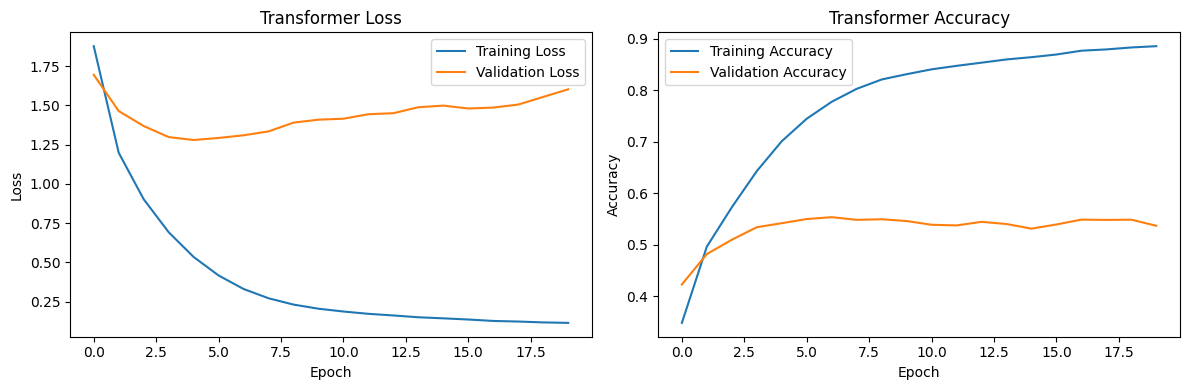

In [124]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Transformer Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history.history["sparse_categorical_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_sparse_categorical_accuracy"],
    label="Validation Accuracy"
)

plt.title("Transformer Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [125]:
# Get French Vocabulary

french_vocabulary = french_vectorizer.get_vocabulary()

start_id = french_vocabulary.index("startseq")
end_id = french_vocabulary.index("endseq")


def translate(sentence):

    # Encode English sentence

    encoder_input = english_vectorizer(
        [sentence]
    )

    # Start Token

    generated_tokens = [start_id]

    for _ in range(max_decoder_length - 1):

        decoder_input = np.zeros(
            (1, max_decoder_length - 1),
            dtype="int64"
        )

        decoder_input[0, :len(generated_tokens)] = generated_tokens

        # Predict Next Token

        predictions = transformer.predict(
            [encoder_input, decoder_input],
            verbose=0
        )

        next_token_logits = predictions[
            0, len(generated_tokens) - 1, :
        ]

        next_token_id = int(
            np.argmax(next_token_logits)
        )

        # Stop at End Token

        if next_token_id == end_id:
            break

        generated_tokens.append(next_token_id)

    # Convert IDs to Words

    translated_words = [
        french_vocabulary[token_id]
        for token_id in generated_tokens[1:]
    ]

    return " ".join(translated_words)

In [126]:
sentences = [
    "I love you",
    "How are you",
    "Good morning",
    "I am happy",
    "Thank you"
]

for sentence in sentences:

    prediction = translate(sentence)

    print("English:", sentence)
    print("French:", prediction)
    print("-" * 40)

English: I love you
French: je tenvie
----------------------------------------
English: How are you
French: comment allezvous 
----------------------------------------
English: Good morning
French: bonjour
----------------------------------------
English: I am happy
French: je suis heureux
----------------------------------------
English: Thank you
French: merci
----------------------------------------


In [127]:
!pip install -q transformers datasets sentencepiece sacrebleu accelerate

In [128]:
import torch

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)

In [129]:
# English Sentences
english_texts = input_texts

# French Sentences
french_texts = [
    text[1:-1].strip()
    for text in target_texts
]

# Create Dataset
dataset = Dataset.from_dict({
    "english": english_texts,
    "french": french_texts
})

# Split Dataset
dataset = dataset.train_test_split(
    test_size=0.2,
    seed=42
)

train_data = dataset["train"]
test_data = dataset["test"]

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['english', 'french'],
        num_rows: 8000
    })
    test: Dataset({
        features: ['english', 'french'],
        num_rows: 2000
    })
})


In [130]:
model_name = "Helsinki-NLP/opus-mt-en-fr"

# Load Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load Model
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("Model Loaded Successfully!")

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Model Loaded Successfully!


In [131]:
def tokenize_data(batch):

    # English Input
    inputs = tokenizer(
        batch["english"],
        max_length=64,
        truncation=True
    )

    # French Target
    targets = tokenizer(
        text_target=batch["french"],
        max_length=64,
        truncation=True
    )

    inputs["labels"] = targets["input_ids"]

    return inputs

In [132]:
tokenized_train = train_data.map(
    tokenize_data,
    batched=True
)

tokenized_test = test_data.map(
    tokenize_data,
    batched=True
)

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [133]:
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model
)

In [134]:
training_args = Seq2SeqTrainingArguments(

    output_dir="./marianmt_results",

    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    num_train_epochs=3,

    eval_strategy="epoch",
    save_strategy="epoch",

    predict_with_generate=True,

    report_to="none"
)

In [135]:
trainer = Seq2SeqTrainer(

    model=model,

    args=training_args,

    train_dataset=tokenized_train,

    eval_dataset=tokenized_test,

    processing_class=tokenizer,

    data_collator=data_collator
)

In [136]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.586114,0.527863
2,0.430337,0.511913
3,0.356955,0.510587


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3000, training_loss=0.4680694325764974, metrics={'train_runtime': 325.1351, 'train_samples_per_second': 73.815, 'train_steps_per_second': 9.227, 'total_flos': 44919570825216.0, 'train_loss': 0.4680694325764974, 'epoch': 3.0})

In [138]:
results = trainer.evaluate()

print(results)

Training Loss,Validation Loss,Epoch
0.356955,0.510587,3


{'eval_loss': 0.5105869770050049}


In [139]:
trainer.save_model("./marianmt_finetuned")

tokenizer.save_pretrained("./marianmt_finetuned")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./marianmt_finetuned/tokenizer_config.json',
 './marianmt_finetuned/vocab.json',
 './marianmt_finetuned/source.spm',
 './marianmt_finetuned/target.spm',
 './marianmt_finetuned/added_tokens.json')

In [143]:
# Select Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Move Model to Device
model = model.to(device)

model.eval()

sentence = "I love artificial intelligence."

# Tokenization
inputs = tokenizer(
    sentence,
    return_tensors="pt"
)

# Move Inputs to Same Device
inputs = inputs.to(device)

# Generate Translation
with torch.no_grad():

    outputs = model.generate(
        **inputs,
        max_length=64
    )

# Decode
translation = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("English:", sentence)
print("French:", translation)

English: I love artificial intelligence.
French: J'adore l'intelligence artificielle.


In [147]:
# Select 5 Training Samples
for i in range(5):

    english = english_sentences[i]

    print("English:", english)
    print("French:", translate(english))
    print("-" * 40)

English: Go.
French: allezy
----------------------------------------
English: Hi.
French: salut
----------------------------------------
English: Run!
French: courez 
----------------------------------------
English: Run!
French: courez 
----------------------------------------
English: Who?
French: qui qui
----------------------------------------


In [148]:
for i in range(10):

    english = english_sentences[i]

    actual = french_sentences[i]

    predicted = translate(english)

    print("English:  ", english)
    print("Actual:   ", actual)
    print("Predicted:", predicted)

    print("-" * 50)

English:   Go.
Actual:    va !
Predicted: allezy
--------------------------------------------------
English:   Hi.
Actual:    salut !
Predicted: salut
--------------------------------------------------
English:   Run!
Actual:    cours !
Predicted: courez 
--------------------------------------------------
English:   Run!
Actual:    courez !
Predicted: courez 
--------------------------------------------------
English:   Who?
Actual:    qui ?
Predicted: qui qui
--------------------------------------------------
English:   Wow!
Actual:    ça alors !
Predicted: ça
--------------------------------------------------
English:   Fire!
Actual:    au feu !
Predicted: au feu
--------------------------------------------------
English:   Help!
Actual:    à l'aide !
Predicted: serstoi
--------------------------------------------------
English:   Jump.
Actual:    saute.
Predicted: saute
--------------------------------------------------
English:   Stop!
Actual:    ça suffit !
Predicted: arrêtetoi
--

In [149]:
def translate(sentence):

    inputs = tokenizer(
        sentence,
        return_tensors="pt",
        truncation=True
    ).to(device)

    model.eval()

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=64,
            num_beams=4,
            repetition_penalty=1.2,
            no_repeat_ngram_size=2,
            early_stopping=True
        )

    return tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

In [150]:
test_sentences = [
    "Go.",
    "Hi.",
    "Run!",
    "Who?",
    "Wow!",
    "Fire!",
    "Help!",
    "Jump.",
    "Stop!",
    "I love you."
]

for sentence in test_sentences:

    prediction = translate(sentence)

    print("English:  ", sentence)
    print("French:   ", prediction)
    print("-" * 45)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

English:   Go.
French:    Allez !
---------------------------------------------
English:   Hi.
French:    Salut !
---------------------------------------------
English:   Run!
French:    Cours !
---------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:   Who?
French:    Qui ?
---------------------------------------------
English:   Wow!
French:    Waouh !
---------------------------------------------
English:   Fire!
French:    Feu !
---------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

English:   Help!
French:    À l'aide !
---------------------------------------------
English:   Jump.
French:    Saute !
---------------------------------------------
English:   Stop!
French:    Arrête !
---------------------------------------------
English:   I love you.
French:    Je t'aime.
---------------------------------------------


In [151]:
for i in range(10):

    english = english_sentences[i]
    actual = french_sentences[i]
    predicted = translate(english)

    print("English:   ", english)
    print("Actual:    ", actual)
    print("Predicted: ", predicted)
    print("-" * 50)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Go.
Actual:     va !
Predicted:  Allez !
--------------------------------------------------
English:    Hi.
Actual:     salut !
Predicted:  Salut !
--------------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Run!
Actual:     cours !
Predicted:  Cours !
--------------------------------------------------
English:    Run!
Actual:     courez !
Predicted:  Cours !
--------------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Who?
Actual:     qui ?
Predicted:  Qui ?
--------------------------------------------------


... (2 outputs left out)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Fire!
Actual:     au feu !
Predicted:  Feu !
--------------------------------------------------
English:    Help!
Actual:     à l'aide !
Predicted:  À l'aide !
--------------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Jump.
Actual:     saute.
Predicted:  Saute !
--------------------------------------------------
English:    Stop!
Actual:     ça suffit !
Predicted:  Arrête !
--------------------------------------------------


In [152]:
transformer.save("transformer_translation.keras")